# Thin-File Credit Scoring: Lending to First-Time Borrowers

## Business problem

Imagine a small-ticket consumer-credit product in India: a **PayLater / buy-now-pay-later line or a small personal loan offered at checkout on an e-commerce platform**. Many of the people who apply are **new to credit**. They have no credit-bureau record, or only a very short one. Two things follow:

* A traditional bureau-score rule ("no score, no loan") **rejects all of them**. That is safe, but it leaves revenue on the table and excludes creditworthy customers. These are often young, salaried or self-employed people, which is the platform's growth segment.
* Approving them blindly is expensive. Unsecured small-ticket loans have high **loss given default** (LGD).

The question is therefore **not** "what is the best AUC?" It is:

> **Using only data we can observe for a first-time borrower (application, demographic, employment, document and contact information), can we approve a meaningful share of thin-file applicants while keeping expected losses at, or below, what we already accept on customers with a credit history?**

## What success looks like

1. A **calibrated probability of default (PD)** for every applicant, including those with no bureau history.
2. An **approval policy** (a PD cut-off) chosen on **expected profit** and on the **approval-rate / expected-loss trade-off**, under explicit business assumptions.
3. A quantified answer to *"how many more thin-file customers can we approve at the same loss rate as the naive 'reject everyone without history' rule?"*
4. Evidence that the policy holds on a **held-out test set** and does not create large unexplained gaps between demographic segments.

Ranking metrics (ROC-AUC, KS, Gini) are reported because risk teams expect them, but they are means to the end above.

**Data:** Kaggle *Home Credit Default Risk*: roughly 307k loan applications with a default label, plus the applicants' credit-bureau records and previous applications. Home Credit serves many unbanked and thin-file customers, so the data is a reasonable stand-in, but it is **not Indian data** (see Limitations).

## 1. Setup

### 1.1 Imports
All libraries are standard open-source packages listed in `requirements.txt`. `NOTEBOOK_START` records the start time so we can check the runtime budget at the end.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
import seaborn as sns
import lightgbm as lgb
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, brier_score_loss
from IPython.display import display, Markdown

NOTEBOOK_START = time.time()
print(f"pandas {pd.__version__} | numpy {np.__version__} | lightgbm {lgb.__version__} | shap {shap.__version__}")

pandas 3.0.6 | numpy 2.3.5 | lightgbm 4.7.0 | shap 0.52.0


### 1.2 Reproducibility and display options
A single random seed (42) is used everywhere: data splits, LightGBM bagging and SHAP sampling. The chart style keeps gridlines light, uses thin marks, and assigns series colours in a fixed order, so a given model keeps the same colour in every chart.

In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 60)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)   # many single-column inserts during feature engineering
warnings.filterwarnings("ignore", category=UserWarning, module="lightgbm")

# Fixed categorical colour order (colour-blind-checked palette); ink colours for text and axes.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 100, "savefig.dpi": 120,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
    "legend.frameon": False,
})

### 1.3 Configuration and business assumptions
Every business number used later lives in this one cell, so the whole analysis can be re-run under different economics.

> ⚠️ **These are illustrative assumptions, not real product economics.** They are round, plausible figures for a small-ticket unsecured loan or PayLater product in India. They exist only to turn model scores into rupees. Section 15 shows how the conclusions move when they change.

Unit economics of one approved loan of size *L*:
* **Repays:** the lender earns `L × MARGIN_RATE` (interest plus fees over the tenor) and pays `L × COST_OF_FUNDS_RATE`.
* **Defaults:** the lender loses `L × LGD` and still pays the cost of funds.

So the expected profit of approving an applicant with default probability *p* is `L × [(1 − p) × margin − p × LGD − cost_of_funds]`. It is positive only when *p* is below the **break-even PD** = `(margin − cost_of_funds) / (margin + LGD)`.

In [3]:
# ── Paths ───────────────────────────────────────────────────────────────────────────
DATA_DIR = Path("./data")
OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ── Illustrative business assumptions (INR) ─────────────────────────────────────────
AVG_LOAN_INR = 25_000            # average amount lent per approved applicant
LOAN_TENOR_MONTHS = 6            # typical tenor of a small-ticket loan / PayLater plan
MARGIN_RATE = 0.16               # interest + fees earned over the tenor, as a share of principal, if the loan repays
COST_OF_FUNDS_ANNUAL = 0.10      # lender's annual cost of capital
LGD = 0.85                       # loss given default: share of principal never recovered (unsecured)

COST_OF_FUNDS_RATE = COST_OF_FUNDS_ANNUAL * LOAN_TENOR_MONTHS / 12   # cost of funds over the tenor
BREAKEVEN_PD = (MARGIN_RATE - COST_OF_FUNDS_RATE) / (MARGIN_RATE + LGD)

# ── Modelling / analysis settings ───────────────────────────────────────────────────
TEST_SIZE = 0.20                 # held out until the very end
VALID_SIZE = 0.20                # model comparison, calibration, threshold choice
EARLY_STOP_SIZE = 0.15           # slice of the training set used only for LightGBM early stopping and the small grid
THRESHOLDS = np.round(np.arange(0, 1.0001, 0.005), 3)   # PD cut-offs evaluated: approve if PD <= threshold
CONSERVATIVE_PROFIT_SHARE = 0.90 # "conservative" policy = lowest cut-off that still earns >= 90% of maximum expected profit
PER_N_APPLICANTS = 1_000         # money figures are reported per 1,000 applicants
SHAP_SAMPLE_SIZE = 3_000         # validation rows explained with SHAP (keeps runtime low)

print(f"Cost of funds over the tenor : {COST_OF_FUNDS_RATE:.2%}")
print(f"Break-even PD                : {BREAKEVEN_PD:.2%}  (approving above this PD loses money on average)")

Cost of funds over the tenor : 5.00%
Break-even PD                : 10.89%  (approving above this PD loses money on average)


### 1.4 Helper functions: metrics and calibration
Scorecard metrics used throughout:
* **KS**: the largest gap between the cumulative score distributions of defaulters and non-defaulters.
* **Gini**: `2 × AUC − 1`, the convention in credit risk.
* **Expected calibration error**: a simple summary of how far predicted PDs are from observed default rates.

`crossfit_isotonic` calibrates scores out of fold, so no calibrated validation score is produced by a calibrator that saw that row's label.

In [4]:
def ks_statistic(y_true, y_score):
    """Kolmogorov–Smirnov statistic of a score.

    The maximum vertical distance between the cumulative distribution of scores for defaulters
    and non-defaulters, equivalent to max(TPR − FPR) over all cut-offs. Range 0–1; higher is better.
    """
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return float(np.max(tpr - fpr))


def gini_coefficient(y_true, y_score):
    """Gini coefficient (accuracy ratio) = 2 × ROC-AUC − 1, the usual credit-scorecard convention."""
    return 2 * roc_auc_score(y_true, y_score) - 1


def score_metrics(y_true, y_score):
    """Return a dict of ROC-AUC, PR-AUC, KS and Gini for one set of scores, plus n and base rate for context."""
    y_true = np.asarray(y_true)
    return {
        "n": len(y_true),
        "default_rate": float(y_true.mean()),
        "roc_auc": roc_auc_score(y_true, y_score),
        "pr_auc": average_precision_score(y_true, y_score),
        "ks": ks_statistic(y_true, y_score),
        "gini": gini_coefficient(y_true, y_score),
    }


def expected_calibration_error(y_true, y_prob, n_bins=10):
    """Expected calibration error with equal-frequency bins.

    Weighted mean absolute gap between the average predicted PD and the observed default rate
    across `n_bins` quantile bins of the prediction. 0 means perfectly calibrated.
    """
    frame = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(y_prob)})
    frame["bin"] = pd.qcut(frame["p"].rank(method="first"), n_bins, labels=False)
    agg = frame.groupby("bin").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    return float(np.average(np.abs(agg["p"] - agg["y"]), weights=agg["n"]))


def crossfit_isotonic(scores, y_true, n_splits=5, seed=42):
    """Isotonic calibration with out-of-fold predictions.

    Returns (calibrated_oof, final_calibrator):
      * calibrated_oof: calibrated scores for the same rows, each produced by a calibrator fitted
        on the other folds, so they are safe to evaluate on and to choose thresholds on;
      * final_calibrator: an IsotonicRegression fitted on all rows, applied later to the test set.
    """
    scores, y_true = np.asarray(scores), np.asarray(y_true)
    oof = np.zeros_like(scores, dtype=float)
    folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for fit_idx, pred_idx in folds.split(scores, y_true):
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
        iso.fit(scores[fit_idx], y_true[fit_idx])
        oof[pred_idx] = iso.predict(scores[pred_idx])
    final = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(scores, y_true)
    return oof, final

### 1.5 Helper functions: business decision analysis
`profit_curve` turns a vector of calibrated PDs into portfolio economics for every candidate cut-off ("approve if PD ≤ threshold"). It uses cumulative sums over sorted PDs, so all 201 thresholds cost one sort. Figures are reported two ways:
* **Expected**: uses the model's PD for each approved applicant. This is what a lender can compute before outcomes are known.
* **Realised**: uses the actual outcomes on the hold-out data, as a sanity check on the expected figures.

In [5]:
def profit_curve(y_true, pd_hat, thresholds=THRESHOLDS, loan=AVG_LOAN_INR, margin=MARGIN_RATE,
                 lgd=LGD, cof=COST_OF_FUNDS_RATE, per_n=PER_N_APPLICANTS):
    """Portfolio economics of the policy "approve if predicted PD <= threshold", for each threshold.

    Expected figures (using calibrated PDs of approved applicants):
        expected revenue = Σ (1 − PD) × loan × margin
        expected loss    = Σ PD × loan × LGD
        funding cost     = n_approved × loan × cost_of_funds
        expected profit  = revenue − loss − funding cost
    Realised profit replaces PD with the observed 0/1 outcome.
    Money columns are INR per `per_n` applicants (approved or not), so segments of different sizes compare.
    """
    y = np.asarray(y_true, dtype=float)
    p = np.asarray(pd_hat, dtype=float)
    order = np.argsort(p, kind="mergesort")
    p_sorted, y_sorted = p[order], y[order]
    cum_pd = np.concatenate([[0.0], np.cumsum(p_sorted)])
    cum_def = np.concatenate([[0.0], np.cumsum(y_sorted)])
    k = np.searchsorted(p_sorted, thresholds, side="right")        # number approved at each threshold
    exp_defaults, real_defaults = cum_pd[k], cum_def[k]

    revenue = (k - exp_defaults) * loan * margin
    loss = exp_defaults * loan * lgd
    funding = k * loan * cof
    realised = (k - real_defaults) * loan * margin - real_defaults * loan * lgd - funding
    scale = per_n / len(p)
    with np.errstate(invalid="ignore", divide="ignore"):
        return pd.DataFrame({
            "threshold": thresholds,
            "n_approved": k,
            "approval_rate": k / len(p),
            "exp_default_rate_approved": np.where(k > 0, exp_defaults / np.maximum(k, 1), np.nan),
            "default_rate_approved": np.where(k > 0, real_defaults / np.maximum(k, 1), np.nan),
            "expected_loss_rate": np.where(k > 0, loss / np.maximum(k * loan, 1), np.nan),
            "expected_revenue": revenue * scale,
            "expected_loss": loss * scale,
            "funding_cost": funding * scale,
            "expected_profit": (revenue - loss - funding) * scale,
            "realised_profit": realised * scale,
        })


def pick_thresholds(curve, share=CONSERVATIVE_PROFIT_SHARE):
    """Return (profit_max_row, conservative_row) from a `profit_curve` table.

    profit_max_row   : threshold with the highest expected profit.
    conservative_row : lowest threshold whose expected profit is at least `share` × the maximum,
                       i.e. fewer approvals and lower losses for a small sacrifice in profit.
    If no threshold is profitable, both rows are the "approve nobody" threshold 0.
    """
    best = curve.loc[curve["expected_profit"].idxmax()]
    if best["expected_profit"] <= 0:
        zero = curve.loc[curve["threshold"].idxmin()]
        return zero, zero
    eligible = curve[curve["expected_profit"] >= share * best["expected_profit"]]
    return best, eligible.loc[eligible["threshold"].idxmin()]


def segment_decision_table(frame, group_col, approved, y_true):
    """Approval rate and default rates by segment for a given approve/decline decision vector.

    `approval_ratio_vs_max` divides each group's approval rate by the highest group's rate: a simple
    disparity screen (values well below ~0.8 deserve a closer look), not a legal test.
    """
    tmp = pd.DataFrame({"group": frame[group_col].values, "approved": np.asarray(approved).astype(int),
                        "y": np.asarray(y_true)}).dropna(subset=["group"])
    out = tmp.groupby("group", observed=True).agg(applicants=("y", "size"), approval_rate=("approved", "mean"),
                                                  default_rate_all=("y", "mean"))
    out["default_rate_approved"] = tmp[tmp["approved"] == 1].groupby("group", observed=True)["y"].mean()
    out["approval_ratio_vs_max"] = out["approval_rate"] / out["approval_rate"].max()
    out.index.name = group_col
    return out

### 1.6 Helper functions: data preparation and plotting
Small utilities: safe division for ratio features, a converter that gives LightGBM categorical columns with levels learned **on training data only**, a formatter for rupee axes, and one reusable "default rate by segment" chart.

In [6]:
def safe_div(numerator, denominator):
    """Element-wise numerator / denominator; zero or missing denominators give NaN instead of inf."""
    return numerator / denominator.replace(0, np.nan)


def make_lgb_frame(X, cat_cols, categories=None):
    """Cast `cat_cols` to pandas 'category' so LightGBM treats them natively.

    Pass categories=None on the training data to learn the levels; pass the returned dict for
    every other split so unseen levels become NaN (no information leaks from validation/test).
    """
    X = X.copy()
    if categories is None:
        categories = {c: sorted(X[c].dropna().unique().tolist()) for c in cat_cols}
    for c in cat_cols:
        X[c] = pd.Categorical(X[c], categories=categories[c])
    return X, categories


def inr(x, _pos=None):
    """Format a rupee amount compactly for chart axes (₹12.3k, ₹1.2L)."""
    if abs(x) >= 1e5:
        return f"₹{x / 1e5:,.1f}L"
    if abs(x) >= 1e3:
        return f"₹{x / 1e3:,.0f}k"
    return f"₹{x:,.0f}"


def plot_default_rate_by(frame, col, title, ylabel, order=None, min_count=500):
    """Horizontal bar chart of default rate by category of `col`, annotated with applicant counts.

    Categories with fewer than `min_count` applicants are dropped (their rates are too noisy to read).
    A dashed line marks the overall default rate. Returns the underlying table.
    """
    stats = frame.groupby(col, observed=True)["TARGET"].agg(default_rate="mean", applicants="size")
    stats = stats[stats["applicants"] >= min_count]
    stats = stats.reindex([o for o in order if o in stats.index]) if order is not None else stats.sort_values("default_rate")
    overall = frame["TARGET"].mean()

    fig, ax = plt.subplots(figsize=(9, 0.5 * len(stats) + 1.8))
    labels = stats.index.astype(str)
    ax.barh(labels, stats["default_rate"], height=0.6, color=PALETTE[0])
    ax.axvline(overall, color=INK_MUTED, linestyle="--", linewidth=1, label=f"Overall default rate ({overall:.1%})")
    for i, (rate, n) in enumerate(zip(stats["default_rate"], stats["applicants"])):
        ax.text(rate + stats["default_rate"].max() * 0.01, i, f"{rate:.1%}  (n = {n:,})", va="center", fontsize=9, color=INK_MUTED)
    ax.set_xlim(0, stats["default_rate"].max() * 1.35)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Default rate (share of applicants with TARGET = 1)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    return stats

## 2. Data loading

### 2.1 Check that the data files exist
`application_train.csv` is required. `bureau.csv` and `previous_application.csv` are optional but recommended: they define thin-file status precisely and feed the credit-history features. If the main file is missing, the cell prints download instructions and stops the notebook without a traceback.

In [7]:
REQUIRED_FILES = {"application_train.csv": True, "bureau.csv": False, "previous_application.csv": False}


class StopExecution(Exception):
    """Raised to halt the notebook quietly (no traceback) when the data is missing."""
    def _render_traceback_(self):
        return []


DOWNLOAD_INSTRUCTIONS = """
The Home Credit data was not found in ./data/. To download it with the Kaggle CLI:

  1. pip install kaggle
  2. Create an API token at https://www.kaggle.com/settings  ->  API  ->  "Generate New Token".
     Newer tokens (starting "KGAT_") go in ~/.kaggle/access_token (or the KAGGLE_API_TOKEN env var);
     legacy tokens go in ~/.kaggle/kaggle.json.   (Windows: C:\\Users\\<you>\\.kaggle\\)
  3. Accept the competition rules (one-time, in the browser):
     https://www.kaggle.com/competitions/home-credit-default-risk/rules
  4. kaggle competitions download -c home-credit-default-risk -p data
  5. Unzip into ./data/
       macOS/Linux : unzip data/home-credit-default-risk.zip -d data
       PowerShell  : Expand-Archive data\\home-credit-default-risk.zip -DestinationPath data

Only application_train.csv is required; bureau.csv and previous_application.csv are recommended.
Then re-run the notebook.
"""

missing_required = [f for f, required in REQUIRED_FILES.items() if required and not (DATA_DIR / f).exists()]
if missing_required:
    print(f"Missing required file(s): {missing_required}")
    print(DOWNLOAD_INSTRUCTIONS)
    raise StopExecution

for fname, required in REQUIRED_FILES.items():
    status = "found" if (DATA_DIR / fname).exists() else ("MISSING" if required else "not found (optional, will use fallbacks)")
    print(f"{fname:<28} {status}")

application_train.csv        found
bureau.csv                   found
previous_application.csv     found


### 2.2 Load the tables
The main table is loaded in full. The two history tables are large (about 1.7M rows each), so only the columns the aggregates need are read, which cuts load time and memory several-fold.

In [8]:
BUREAU_COLS = ["SK_ID_CURR", "CREDIT_ACTIVE", "DAYS_CREDIT", "CREDIT_DAY_OVERDUE", "AMT_CREDIT_SUM",
               "AMT_CREDIT_SUM_DEBT", "AMT_CREDIT_SUM_OVERDUE", "CNT_CREDIT_PROLONG"]
PREV_COLS = ["SK_ID_CURR", "NAME_CONTRACT_STATUS", "AMT_APPLICATION", "AMT_CREDIT", "DAYS_DECISION", "CNT_PAYMENT"]

t0 = time.time()
app = pd.read_csv(DATA_DIR / "application_train.csv")
bureau = pd.read_csv(DATA_DIR / "bureau.csv", usecols=BUREAU_COLS) if (DATA_DIR / "bureau.csv").exists() else None
prev = (pd.read_csv(DATA_DIR / "previous_application.csv", usecols=PREV_COLS)
        if (DATA_DIR / "previous_application.csv").exists() else None)
print(f"Loaded in {time.time() - t0:.1f}s")

Loaded in 5.7s


### 2.3 Shapes and memory usage
A quick check that the files are complete: the main table should have about 307.5k rows and 122 columns.

In [9]:
for name, frame in {"application_train": app, "bureau": bureau, "previous_application": prev}.items():
    if frame is None:
        print(f"{name:<22} not loaded")
        continue
    print(f"{name:<22} rows = {frame.shape[0]:>10,}  cols = {frame.shape[1]:>4}  "
          f"memory = {frame.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

application_train      rows =    307,511  cols =  122  memory = 341 MB
bureau                 rows =  1,716,428  cols =    8  memory = 120 MB
previous_application   rows =  1,670,214  cols =    6  memory = 93 MB


### 2.4 Target balance
Defaults are the minority class, so accuracy would be a meaningless metric. This is also why we report PR-AUC next to ROC-AUC.

In [10]:
target_balance = app["TARGET"].value_counts().rename_axis("TARGET").to_frame("applicants")
target_balance["share"] = target_balance["applicants"] / len(app)
display(target_balance)
BASE_DEFAULT_RATE = app["TARGET"].mean()
print(f"Overall default rate: {BASE_DEFAULT_RATE:.2%}")

,applicants,share
TARGET,,
0,282686,0.919271
1,24825,0.080729


Overall default rate: 8.07%


## 3. Data quality

### 3.1 Missing values
Many columns describe the applicant's building (`*_AVG`, `*_MODE`, `*_MEDI`) and are mostly empty. We keep them: LightGBM handles missing values natively, and the logistic-regression pipeline imputes them and adds "was missing" indicators, because missingness itself can carry signal.

In [11]:
missing = app.isna().mean().sort_values(ascending=False)
print(f"Columns with any missing values : {(missing > 0).sum()} of {app.shape[1]}")
print(f"Columns more than 50% missing   : {(missing > 0.5).sum()}")
missing_table = missing[missing > 0].head(15).to_frame("missing_share")
missing_table["dtype"] = app.dtypes[missing_table.index].astype(str)
display(missing_table.style.format({"missing_share": "{:.1%}"}))

Columns with any missing values : 67 of 122
Columns more than 50% missing   : 41


,missing_share,dtype
COMMONAREA_AVG,69.9%,float64
COMMONAREA_MODE,69.9%,float64
COMMONAREA_MEDI,69.9%,float64
NONLIVINGAPARTMENTS_MEDI,69.4%,float64
NONLIVINGAPARTMENTS_MODE,69.4%,float64
NONLIVINGAPARTMENTS_AVG,69.4%,float64
FONDKAPREMONT_MODE,68.4%,str
LIVINGAPARTMENTS_AVG,68.4%,float64
LIVINGAPARTMENTS_MEDI,68.4%,float64
LIVINGAPARTMENTS_MODE,68.4%,float64


### 3.2 Duplicate check
Each application should appear once. We check for duplicate IDs and for duplicate rows once the ID is ignored.

In [12]:
n_dup_ids = app["SK_ID_CURR"].duplicated().sum()
n_dup_rows = app.drop(columns=["SK_ID_CURR"]).duplicated().sum()
print(f"Duplicate SK_ID_CURR values          : {n_dup_ids:,}")
print(f"Duplicate rows (ignoring the ID)     : {n_dup_rows:,}")

Duplicate SK_ID_CURR values          : 0
Duplicate rows (ignoring the ID)     : 0


### 3.3 Anomaly: the `DAYS_EMPLOYED = 365243` placeholder
`DAYS_EMPLOYED` counts days before the application, so it should be negative. The value 365243 (about +1,000 years) is a placeholder, used mostly for pensioners and unemployed applicants. We check how common it is and whether those applicants default at a different rate.

In [13]:
employed_anom = app["DAYS_EMPLOYED"] == 365243
print(f"Rows with DAYS_EMPLOYED = 365243: {employed_anom.sum():,} ({employed_anom.mean():.1%})")
print("\nDefault rate, placeholder vs. real value:")
display(app.groupby(employed_anom)["TARGET"].mean().rename(index={True: "placeholder", False: "real value"}).to_frame("default_rate"))
print("Income type of placeholder rows:")
display(app.loc[employed_anom, "NAME_INCOME_TYPE"].value_counts().to_frame("applicants"))

Rows with DAYS_EMPLOYED = 365243: 55,374 (18.0%)

Default rate, placeholder vs. real value:


,default_rate
DAYS_EMPLOYED,
real value,0.086600
placeholder,0.053996


Income type of placeholder rows:


,applicants
NAME_INCOME_TYPE,
Pensioner,55352
Unemployed,22


### 3.4 Fix: replace the placeholder with NaN plus an explicit flag
If the placeholder stayed as a number, a model would treat it as extremely long employment. We keep its information (the rate differs) in a binary flag and set the value itself to missing.

In [14]:
app["DAYS_EMPLOYED_ANOM"] = employed_anom.astype(int)
app.loc[employed_anom, "DAYS_EMPLOYED"] = np.nan
print(f"DAYS_EMPLOYED max after fix: {app['DAYS_EMPLOYED'].max():,.0f} (should be <= 0)")

DAYS_EMPLOYED max after fix: 0 (should be <= 0)


### 3.5 Other anomalies: unknown-category codes and extreme incomes
`CODE_GENDER` uses `XNA` and `NAME_FAMILY_STATUS` uses `Unknown` for a handful of rows. Income has a very long right tail.

In [15]:
print("CODE_GENDER:", app["CODE_GENDER"].value_counts().to_dict())
print("NAME_FAMILY_STATUS 'Unknown':", (app["NAME_FAMILY_STATUS"] == "Unknown").sum())
print("\nAMT_INCOME_TOTAL quantiles:")
display(app["AMT_INCOME_TOTAL"].quantile([0.5, 0.99, 0.999, 1.0]).to_frame("income").style.format("{:,.0f}"))

CODE_GENDER: {'F': 202448, 'M': 105059, 'XNA': 4}
NAME_FAMILY_STATUS 'Unknown': 2

AMT_INCOME_TOTAL quantiles:


,income
0.500000,"147,150"
0.990000,"472,500"
0.999000,"900,000"
1.000000,"117,000,000"


### 3.6 Fix: treat unknown codes as missing
The `XNA` and `Unknown` codes become NaN. We do **not** clip incomes using quantiles from the full dataset, because that would leak information from the test rows. Tree models are insensitive to outliers anyway, and the logistic-regression pipeline clips standardised values using training-set statistics only.

In [16]:
app["CODE_GENDER"] = app["CODE_GENDER"].replace("XNA", np.nan)
app["NAME_FAMILY_STATUS"] = app["NAME_FAMILY_STATUS"].replace("Unknown", np.nan)
print("CODE_GENDER after fix:", app["CODE_GENDER"].value_counts(dropna=False).to_dict())

CODE_GENDER after fix: {'F': 202448, 'M': 105059, nan: 4}


## 4. Exploratory analysis: default rate by segment

Descriptive only: no feature is selected from these charts, so looking at the full dataset here does not leak information into the models.

### 4.1 Age bands
Age is stored as negative days. We bucket it into bands used both in this EDA and in the fairness check later. The band is a reporting column and is **not** a model feature; the model uses continuous age.

In [17]:
AGE_BAND_ORDER = ["<25", "25-34", "35-44", "45-54", "55+"]
app["AGE_BAND"] = pd.cut(-app["DAYS_BIRTH"] / 365.25, bins=[0, 25, 35, 45, 55, 120],
                         labels=AGE_BAND_ORDER, right=False)
display(app["AGE_BAND"].value_counts().reindex(AGE_BAND_ORDER).to_frame("applicants"))

,applicants
AGE_BAND,
<25,12233
25-34,72429
35-44,84261
45-54,70190
55+,68398


### 4.2 Default rate by income type
Categories with fewer than 500 applicants (students, businessmen, maternity leave) are hidden because their rates are too noisy to read.

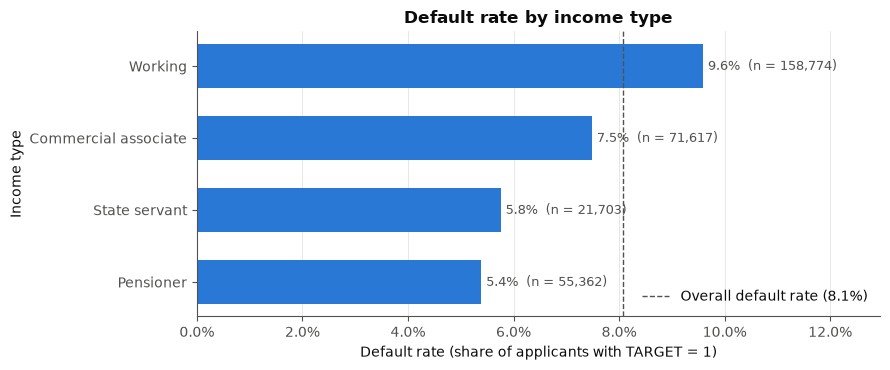

In [18]:
_ = plot_default_rate_by(app, "NAME_INCOME_TYPE", "Default rate by income type", "Income type")

**Takeaway:** Salaried "Working" applicants default most (9.6%) and pensioners least (5.4%). Income type is available for every first-time borrower, so it is a genuine alternative-data signal.

### 4.3 Default rate by education

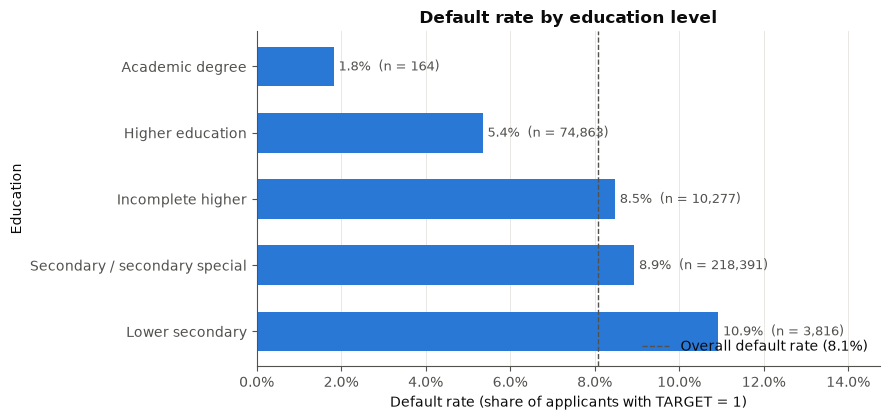

In [19]:
EDU_ORDER = ["Lower secondary", "Secondary / secondary special", "Incomplete higher", "Higher education", "Academic degree"]
_ = plot_default_rate_by(app, "NAME_EDUCATION_TYPE", "Default rate by education level", "Education", order=EDU_ORDER, min_count=100)

**Takeaway:** Default risk falls steadily with education (10.9% for lower secondary vs. 5.4% for higher education). The "Academic degree" bar rests on only 164 applicants.

### 4.4 Default rate by age band

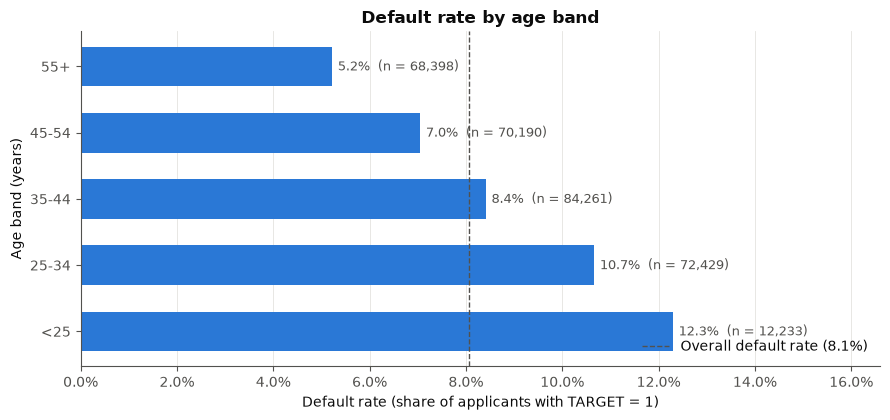

In [20]:
_ = plot_default_rate_by(app, "AGE_BAND", "Default rate by age band", "Age band (years)", order=AGE_BAND_ORDER)

**Takeaway:** Risk falls monotonically with age, from 12.3% under 25 to 5.2% at 55+. The youngest bands are exactly the new-to-credit customers this product targets, so age needs careful handling (see the fairness section).

### 4.5 Default rate by region rating
`REGION_RATING_CLIENT` is Home Credit's own rating of the applicant's region (1 = best, 3 = worst).

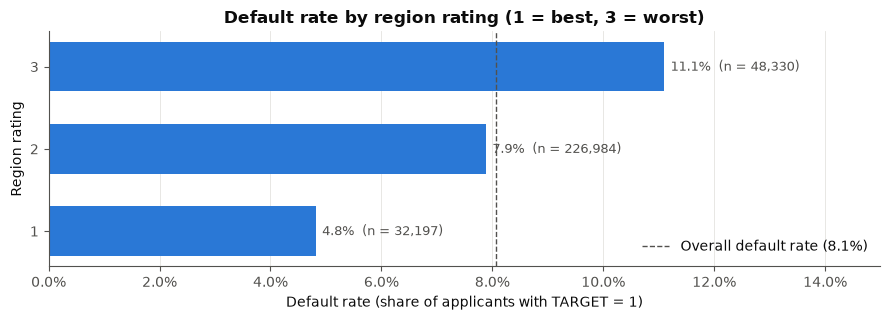

In [21]:
_ = plot_default_rate_by(app, "REGION_RATING_CLIENT", "Default rate by region rating (1 = best, 3 = worst)",
                         "Region rating", order=[1, 2, 3])

**Takeaway:** Region rating separates risk strongly (4.8% â†’ 7.9% â†’ 11.1%). Because it may proxy for socio-economic status, it is monitored in the fairness check.

### 4.6 Default rate by contract type
Cash loans compared with revolving loans (a credit line, the closest analogue to a PayLater limit).

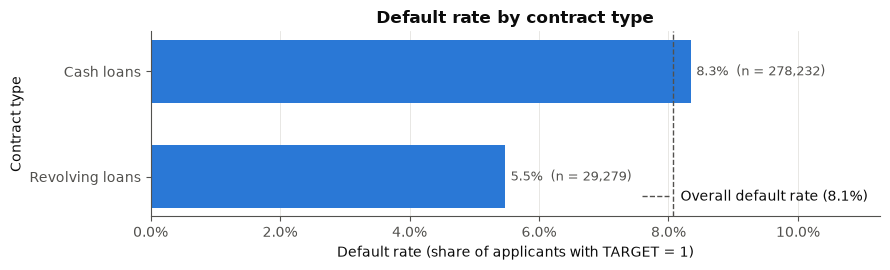

In [22]:
_ = plot_default_rate_by(app, "NAME_CONTRACT_TYPE", "Default rate by contract type", "Contract type")

**Takeaway:** Revolving loans, the closest analogue to a PayLater line, default less than cash loans (5.5% vs. 8.4%).

## 5. Defining "thin-file"

A **thin-file applicant** here is one with **no record in the credit bureau** (`bureau.csv`). That is exactly the customer a bureau-score rule cannot assess. We also mark whether the applicant has **previous applications** with the lender, and show every combination.

If `bureau.csv` is not available, the fallback proxy is "all `AMT_REQ_CREDIT_BUREAU_*` enquiry counts are missing", which Home Credit records when the bureau returned nothing.

### 5.1 Build the history flags

In [23]:
if bureau is not None:
    app["HAS_BUREAU"] = app["SK_ID_CURR"].isin(bureau["SK_ID_CURR"]).astype(int)
else:
    app["HAS_BUREAU"] = app["AMT_REQ_CREDIT_BUREAU_YEAR"].notna().astype(int)
    print("bureau.csv not loaded: using the AMT_REQ_CREDIT_BUREAU_* proxy for bureau history")

if prev is not None:
    app["HAS_PREV_APP"] = app["SK_ID_CURR"].isin(prev["SK_ID_CURR"]).astype(int)
else:
    app["HAS_PREV_APP"] = np.nan
    print("previous_application.csv not loaded: previous-application flag unavailable")

app["THIN_FILE"] = 1 - app["HAS_BUREAU"]
app["SEGMENT"] = np.where(app["THIN_FILE"] == 1, "Thin-file (no bureau history)", "Has bureau history")
print(f"Thin-file applicants: {app['THIN_FILE'].sum():,} ({app['THIN_FILE'].mean():.1%} of all applicants)")

Thin-file applicants: 44,020 (14.3% of all applicants)


### 5.2 Segment sizes and default rates: bureau history × previous applications

In [24]:
history_table = (app.groupby(["HAS_BUREAU", "HAS_PREV_APP"], dropna=False)["TARGET"]
                 .agg(applicants="size", default_rate="mean"))
history_table["share_of_applicants"] = history_table["applicants"] / len(app)
display(history_table.style.format({"applicants": "{:,}", "default_rate": "{:.2%}", "share_of_applicants": "{:.1%}"}))

### 5.3 Thin-file vs. everyone else
This is the headline comparison for the business case: how large the thin-file segment is and how much riskier it is on average.

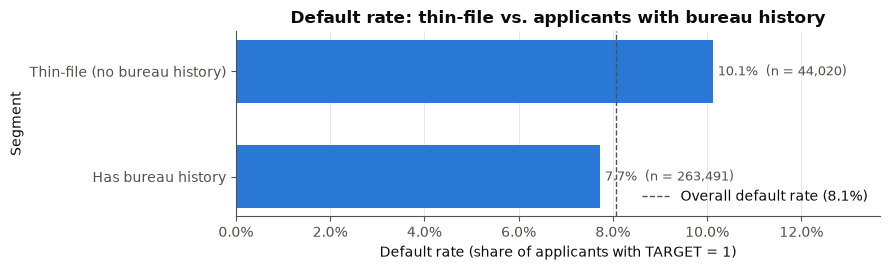

Thin-file share of applicants: 14.3%
Default rate: thin-file 10.12% vs. with history 7.73% (relative risk 1.31x)


In [25]:
thin_stats = plot_default_rate_by(app, "SEGMENT", "Default rate: thin-file vs. applicants with bureau history", "Segment")
THIN_SHARE = app["THIN_FILE"].mean()
THIN_DEFAULT_RATE = app.loc[app["THIN_FILE"] == 1, "TARGET"].mean()
HIST_DEFAULT_RATE = app.loc[app["THIN_FILE"] == 0, "TARGET"].mean()
print(f"Thin-file share of applicants: {THIN_SHARE:.1%}")
print(f"Default rate: thin-file {THIN_DEFAULT_RATE:.2%} vs. with history {HIST_DEFAULT_RATE:.2%} "
      f"(relative risk {THIN_DEFAULT_RATE / HIST_DEFAULT_RATE:.2f}x)")

**Takeaway:** Thin-file applicants are 14.3% of applications and default at 10.12% vs. 7.73%, about 1.3Ã— the risk. Riskier on average, but far from a segment that should be rejected wholesale.

## 6. Feature engineering

Every feature below is computed **row by row** or **per applicant from that applicant's own history**. None uses the target or statistics pooled across applicants, so building them before the split cannot leak information between train, validation and test.

### 6.1 (a) Affordability ratios
Loan size relative to income is the first thing an underwriter looks at, and all of these fields are available for a first-time borrower.

In [26]:
app["CREDIT_TO_INCOME"] = safe_div(app["AMT_CREDIT"], app["AMT_INCOME_TOTAL"])
app["ANNUITY_TO_INCOME"] = safe_div(app["AMT_ANNUITY"], app["AMT_INCOME_TOTAL"])      # instalment burden
app["CREDIT_TO_GOODS"] = safe_div(app["AMT_CREDIT"], app["AMT_GOODS_PRICE"])          # >1 means financing more than the goods
app["ANNUITY_TO_CREDIT"] = safe_div(app["AMT_ANNUITY"], app["AMT_CREDIT"])            # ≈ 1 / tenor
app["INCOME_PER_PERSON"] = safe_div(app["AMT_INCOME_TOTAL"], app["CNT_FAM_MEMBERS"])
display(app[["CREDIT_TO_INCOME", "ANNUITY_TO_INCOME", "CREDIT_TO_GOODS", "ANNUITY_TO_CREDIT", "INCOME_PER_PERSON"]]
        .describe().T.style.format("{:,.3f}"))

,count,mean,std,min,25%,50%,75%,max
CREDIT_TO_INCOME,"307,511.000",3.958,2.690,0.005,2.019,3.265,5.160,84.737
ANNUITY_TO_INCOME,"307,499.000",0.181,0.095,0.000,0.115,0.163,0.229,1.876
CREDIT_TO_GOODS,"307,233.000",1.123,0.124,0.150,1.000,1.119,1.198,6.000
ANNUITY_TO_CREDIT,"307,499.000",0.054,0.022,0.022,0.037,0.050,0.064,0.124
INCOME_PER_PERSON,"307,509.000","93,105.880","101,373.363","2,812.500","47,250.000","75,000.000","112,500.000","39,000,000.000"


### 6.2 (b) Age and employment stability
Day counts are converted to years. Their ratios capture stability: the share of adult life spent in the current job, and how recently the phone number, ID document or registration changed.

In [27]:
app["AGE_YEARS"] = -app["DAYS_BIRTH"] / 365.25
app["EMPLOYED_YEARS"] = -app["DAYS_EMPLOYED"] / 365.25
app["EMPLOYED_TO_AGE"] = safe_div(app["EMPLOYED_YEARS"], app["AGE_YEARS"])
app["YEARS_SINCE_ID_CHANGE"] = -app["DAYS_ID_PUBLISH"] / 365.25
app["YEARS_SINCE_REGISTRATION"] = -app["DAYS_REGISTRATION"] / 365.25
app["YEARS_SINCE_PHONE_CHANGE"] = -app["DAYS_LAST_PHONE_CHANGE"] / 365.25
app["CAR_AGE_TO_AGE"] = safe_div(app["OWN_CAR_AGE"], app["AGE_YEARS"])
display(app[["AGE_YEARS", "EMPLOYED_YEARS", "EMPLOYED_TO_AGE", "YEARS_SINCE_PHONE_CHANGE"]].describe().T.style.format("{:,.2f}"))

,count,mean,std,min,25%,50%,75%,max
AGE_YEARS,"307,511.00",43.91,11.95,20.50,33.98,43.12,53.89,69.07
EMPLOYED_YEARS,"252,137.00",6.53,6.40,-0.00,2.10,4.51,8.69,49.04
EMPLOYED_TO_AGE,"252,137.00",0.16,0.13,-0.00,0.06,0.12,0.22,0.73
YEARS_SINCE_PHONE_CHANGE,"307,510.00",2.64,2.26,-0.00,0.75,2.07,4.30,11.75


### 6.3 (c) Document and contact-flag aggregates
Home Credit records which of 20 documents were supplied and which contact channels were given. The counts summarise *how much the applicant engaged with verification*, a typical alternative-data signal. Address mismatches (living, registered and working in different places) summarise residential stability.

In [28]:
DOC_COLS = [c for c in app.columns if c.startswith("FLAG_DOCUMENT_")]
CONTACT_COLS = ["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE", "FLAG_CONT_MOBILE", "FLAG_PHONE", "FLAG_EMAIL"]
ADDRESS_COLS = ["REG_REGION_NOT_LIVE_REGION", "REG_REGION_NOT_WORK_REGION", "LIVE_REGION_NOT_WORK_REGION",
                "REG_CITY_NOT_LIVE_CITY", "REG_CITY_NOT_WORK_CITY", "LIVE_CITY_NOT_WORK_CITY"]

app["DOCUMENT_COUNT"] = app[DOC_COLS].sum(axis=1)
app["CONTACT_COUNT"] = app[CONTACT_COLS].sum(axis=1)
app["ADDRESS_MISMATCH_COUNT"] = app[ADDRESS_COLS].sum(axis=1)
display(app[["DOCUMENT_COUNT", "CONTACT_COUNT", "ADDRESS_MISMATCH_COUNT"]].describe().T.style.format("{:,.2f}"))

,count,mean,std,min,25%,50%,75%,max
DOCUMENT_COUNT,"307,511.00",0.93,0.34,0.00,1.00,1.00,1.00,4.00
CONTACT_COUNT,"307,511.00",3.36,0.87,1.00,3.00,3.00,4.00,6.00
ADDRESS_MISMATCH_COUNT,"307,511.00",0.59,1.08,0.00,0.00,0.00,2.00,6.00


### 6.4 (d) External scores (`EXT_SOURCE_*`) and their interactions
`EXT_SOURCE_1/2/3` are normalised scores from undisclosed external sources. They are the strongest predictors in this dataset, and their summaries and products are standard features. **Because they are most plausibly bureau-style credit scores, we treat them as credit-history data.** They are excluded from the alternative-data model (section 7). A real Indian thin-file applicant would normally have no CIBIL-type score at all.

The coverage table shows whether the scores exist for thin-file applicants in this dataset.

In [29]:
EXT_COLS = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
app["EXT_SOURCE_MEAN"] = app[EXT_COLS].mean(axis=1)
app["EXT_SOURCE_MIN"] = app[EXT_COLS].min(axis=1)
app["EXT_SOURCE_MAX"] = app[EXT_COLS].max(axis=1)
app["EXT_SOURCE_STD"] = app[EXT_COLS].std(axis=1)
app["EXT_SOURCE_N_MISSING"] = app[EXT_COLS].isna().sum(axis=1)
app["EXT_SOURCE_1_X_2"] = app["EXT_SOURCE_1"] * app["EXT_SOURCE_2"]
app["EXT_SOURCE_2_X_3"] = app["EXT_SOURCE_2"] * app["EXT_SOURCE_3"]
app["EXT_SOURCE_1_X_3"] = app["EXT_SOURCE_1"] * app["EXT_SOURCE_3"]
app["EXT_SOURCE_MEAN_X_ANNUITY_TO_CREDIT"] = app["EXT_SOURCE_MEAN"] * app["ANNUITY_TO_CREDIT"]

display(app.groupby("SEGMENT")[EXT_COLS].apply(lambda g: g.notna().mean()).style.format("{:.1%}")
        .set_caption("Share of applicants with each external score available"))

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
SEGMENT,,,
Has bureau history,44.4%,99.8%,93.1%
Thin-file (no bureau history),39.2%,99.7%,3.1%


### 6.5 (e) Credit-bureau aggregates (optional)
One row per applicant from `bureau.csv`: the number of past credits, how many are active, the length of history, debt levels and overdue behaviour. Thin-file applicants get a count of 0 and missing values elsewhere. **All `BUR_*` features are credit-history data.**

In [30]:
if bureau is not None:
    b = bureau.assign(IS_ACTIVE=(bureau["CREDIT_ACTIVE"] == "Active").astype(int))
    bureau_agg = b.groupby("SK_ID_CURR").agg(
        BUR_LOAN_COUNT=("DAYS_CREDIT", "size"),
        BUR_ACTIVE_COUNT=("IS_ACTIVE", "sum"),
        BUR_DAYS_CREDIT_MAX=("DAYS_CREDIT", "max"),        # most recent credit
        BUR_DAYS_CREDIT_MIN=("DAYS_CREDIT", "min"),        # oldest credit = length of history
        BUR_CREDIT_SUM=("AMT_CREDIT_SUM", "sum"),
        BUR_DEBT_SUM=("AMT_CREDIT_SUM_DEBT", "sum"),
        BUR_OVERDUE_SUM=("AMT_CREDIT_SUM_OVERDUE", "sum"),
        BUR_MAX_DAYS_OVERDUE=("CREDIT_DAY_OVERDUE", "max"),
        BUR_PROLONG_SUM=("CNT_CREDIT_PROLONG", "sum"),
    )
    bureau_agg["BUR_ACTIVE_SHARE"] = bureau_agg["BUR_ACTIVE_COUNT"] / bureau_agg["BUR_LOAN_COUNT"]
    bureau_agg["BUR_DEBT_TO_CREDIT"] = safe_div(bureau_agg["BUR_DEBT_SUM"], bureau_agg["BUR_CREDIT_SUM"])
    app = app.merge(bureau_agg, left_on="SK_ID_CURR", right_index=True, how="left")
    app[["BUR_LOAN_COUNT", "BUR_ACTIVE_COUNT"]] = app[["BUR_LOAN_COUNT", "BUR_ACTIVE_COUNT"]].fillna(0)
    print(f"Added {bureau_agg.shape[1]} bureau features for {len(bureau_agg):,} applicants")
    del b, bureau_agg
else:
    print("bureau.csv not loaded: skipping bureau aggregates")

Added 11 bureau features for 305,811 applicants


### 6.6 (e) Previous-application aggregates (optional)
One row per applicant from `previous_application.csv`: how often they applied before, how often they were approved or refused, and the typical amounts. **All `PREV_*` features are prior-credit-history data.**

In [31]:
if prev is not None:
    p = prev.assign(IS_APPROVED=(prev["NAME_CONTRACT_STATUS"] == "Approved").astype(int),
                    IS_REFUSED=(prev["NAME_CONTRACT_STATUS"] == "Refused").astype(int))
    prev_agg = p.groupby("SK_ID_CURR").agg(
        PREV_APP_COUNT=("DAYS_DECISION", "size"),
        PREV_APPROVED_COUNT=("IS_APPROVED", "sum"),
        PREV_REFUSED_COUNT=("IS_REFUSED", "sum"),
        PREV_AMT_APPLICATION_MEAN=("AMT_APPLICATION", "mean"),
        PREV_AMT_CREDIT_MEAN=("AMT_CREDIT", "mean"),
        PREV_DAYS_DECISION_MAX=("DAYS_DECISION", "max"),   # most recent application
        PREV_CNT_PAYMENT_MEAN=("CNT_PAYMENT", "mean"),
    )
    prev_agg["PREV_REFUSED_SHARE"] = prev_agg["PREV_REFUSED_COUNT"] / prev_agg["PREV_APP_COUNT"]
    prev_agg["PREV_CREDIT_TO_APPLICATION"] = safe_div(prev_agg["PREV_AMT_CREDIT_MEAN"], prev_agg["PREV_AMT_APPLICATION_MEAN"])
    app = app.merge(prev_agg, left_on="SK_ID_CURR", right_index=True, how="left")
    app["PREV_APP_COUNT"] = app["PREV_APP_COUNT"].fillna(0)
    print(f"Added {prev_agg.shape[1]} previous-application features for {len(prev_agg):,} applicants")
    del p, prev_agg
else:
    print("previous_application.csv not loaded: skipping previous-application aggregates")

Added 9 previous-application features for 338,857 applicants


### 6.7 Free memory and downcast
The raw history tables are no longer needed. Downcasting floats to 32-bit roughly halves memory and speeds up training without any meaningful loss of precision.

In [32]:
del bureau, prev
float_cols = app.select_dtypes("float64").columns
app[float_cols] = app[float_cols].astype("float32")
print(f"Modelling table: {app.shape[0]:,} rows x {app.shape[1]} columns, "
      f"{app.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

Modelling table: 307,511 rows x 172 columns, 338 MB


## 7. Two feature sets: the core comparison

| Feature set | Contents | Use case |
|---|---|---|
| **Full** | Everything, including bureau aggregates, previous applications, bureau enquiry counts and the `EXT_SOURCE` scores | Upper bound: what we could do if every applicant had a credit history |
| **Alternative-data only** | Application form, demographics, employment, income and loan structure, documents, contact channels, address stability, region, housing, and the social-circle counts | What we can actually use for a **first-time borrower** |

Deliberate exclusions from **both** sets:
* **`CODE_GENDER`** is not a model input. It is kept only for the fairness audit (responsible lending).
* ID, target, reporting columns (`AGE_BAND`, `SEGMENT`, `THIN_FILE`) and raw `DAYS_*` columns (replaced by the year-based versions).

Note that the `*_SOCIAL_CIRCLE` counts describe defaults *among the applicant's social circle*, not the applicant's own credit history, so they stay in the alternative-data set.

In [33]:
NON_FEATURES = ["SK_ID_CURR", "TARGET", "THIN_FILE", "SEGMENT", "AGE_BAND"]
PROTECTED_ATTRIBUTES = ["CODE_GENDER"]
RAW_DAYS = ["DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_ID_PUBLISH", "DAYS_REGISTRATION", "DAYS_LAST_PHONE_CHANGE"]


def is_credit_history_feature(col):
    """True if a column is derived from the credit bureau or the applicant's prior credit history."""
    return (col.startswith(("BUR_", "PREV_", "EXT_SOURCE", "AMT_REQ_CREDIT_BUREAU_"))
            or col in {"HAS_BUREAU", "HAS_PREV_APP"})


FEATURES_FULL = [c for c in app.columns if c not in NON_FEATURES + PROTECTED_ATTRIBUTES + RAW_DAYS]
FEATURES_FULL = [c for c in FEATURES_FULL if app[c].notna().any()]
FEATURES_ALT = [c for c in FEATURES_FULL if not is_credit_history_feature(c)]
CAT_COLS = [c for c in FEATURES_FULL if not pd.api.types.is_numeric_dtype(app[c])]
FEATURE_SETS = {"Full": FEATURES_FULL, "Alternative-data": FEATURES_ALT}

print(f"Full feature set             : {len(FEATURES_FULL)} features ({len(CAT_COLS)} categorical)")
print(f"Alternative-data feature set : {len(FEATURES_ALT)} features")
print(f"Credit-history features excluded from the alternative set ({len(FEATURES_FULL) - len(FEATURES_ALT)}):")
print(sorted(set(FEATURES_FULL) - set(FEATURES_ALT)))

Full feature set             : 161 features (15 categorical)
Alternative-data feature set : 121 features
Credit-history features excluded from the alternative set (40):
['AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'BUR_ACTIVE_COUNT', 'BUR_ACTIVE_SHARE', 'BUR_CREDIT_SUM', 'BUR_DAYS_CREDIT_MAX', 'BUR_DAYS_CREDIT_MIN', 'BUR_DEBT_SUM', 'BUR_DEBT_TO_CREDIT', 'BUR_LOAN_COUNT', 'BUR_MAX_DAYS_OVERDUE', 'BUR_OVERDUE_SUM', 'BUR_PROLONG_SUM', 'EXT_SOURCE_1', 'EXT_SOURCE_1_X_2', 'EXT_SOURCE_1_X_3', 'EXT_SOURCE_2', 'EXT_SOURCE_2_X_3', 'EXT_SOURCE_3', 'EXT_SOURCE_MAX', 'EXT_SOURCE_MEAN', 'EXT_SOURCE_MEAN_X_ANNUITY_TO_CREDIT', 'EXT_SOURCE_MIN', 'EXT_SOURCE_N_MISSING', 'EXT_SOURCE_STD', 'HAS_BUREAU', 'HAS_PREV_APP', 'PREV_AMT_APPLICATION_MEAN', 'PREV_AMT_CREDIT_MEAN', 'PREV_APPROVED_COUNT', 'PREV_APP_COUNT', 'PREV_CNT_PAYMENT_MEAN', 'PREV_CREDIT_TO_APPLICATION', 'PREV_DA

## 8. Train / validation / test split

A stratified split on **target × thin-file status**, so every split has the same default rate *and* the same share of thin-file applicants:

| Split | Share | Used for |
|---|---|---|
| Train | 60% | Fitting all models and preprocessing. For LightGBM, 15% of it is set aside for early stopping and the small grid search |
| Validation | 20% | Comparing models, calibration, SHAP, choosing the threshold, sensitivity and fairness |
| Test | 20% | **Touched once**, in section 17, with everything already frozen |

Imputation, scaling, encoding and category levels are all fitted on training rows only.

In [34]:
strata = app["TARGET"].astype(str) + "_" + app["THIN_FILE"].astype(str)
idx_trainval, idx_test = train_test_split(app.index, test_size=TEST_SIZE, stratify=strata, random_state=RANDOM_SEED)
idx_train, idx_valid = train_test_split(idx_trainval, test_size=VALID_SIZE / (1 - TEST_SIZE),
                                        stratify=strata[idx_trainval], random_state=RANDOM_SEED)
idx_fit, idx_es = train_test_split(idx_train, test_size=EARLY_STOP_SIZE,
                                   stratify=strata[idx_train], random_state=RANDOM_SEED)

train_df, valid_df, test_df = app.loc[idx_train], app.loc[idx_valid], app.loc[idx_test]
y_train, y_valid, y_test = train_df["TARGET"].values, valid_df["TARGET"].values, test_df["TARGET"].values
thin_valid, thin_test = valid_df["THIN_FILE"].values == 1, test_df["THIN_FILE"].values == 1

split_summary = pd.DataFrame({
    name: {"rows": len(frame), "share": len(frame) / len(app), "default_rate": frame["TARGET"].mean(),
           "thin_file_share": frame["THIN_FILE"].mean()}
    for name, frame in {"train": train_df, " ↳ LightGBM fit": app.loc[idx_fit], " ↳ early stopping": app.loc[idx_es],
                        "validation": valid_df, "test": test_df}.items()}).T
display(split_summary.style.format({"rows": "{:,.0f}", "share": "{:.1%}", "default_rate": "{:.2%}", "thin_file_share": "{:.1%}"}))

,rows,share,default_rate,thin_file_share
train,"184,506",60.0%,8.07%,14.3%
↳ LightGBM fit,"156,830",51.0%,8.07%,14.3%
↳ early stopping,"27,676",9.0%,8.07%,14.3%
validation,"61,502",20.0%,8.07%,14.3%
test,"61,503",20.0%,8.07%,14.3%


## 9. Baseline: logistic regression

### 9.1 Pipeline definition
An sklearn `Pipeline` with all preprocessing inside, so it is fitted on the training rows only:
* **numeric**: median imputation plus missing-value indicators, then standardisation, then clipping to ±5 standard deviations (tames the extreme incomes);
* **categorical**: a constant "MISSING" level, then one-hot encoding, with rare levels (< 0.5% of rows) grouped;
* **model**: L2-regularised logistic regression.

In [35]:
def build_logreg_pipeline(num_cols, cat_cols, C=0.05):
    """Imputation + scaling + one-hot encoding + logistic regression, all fitted inside one sklearn Pipeline."""
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
        ("clip", FunctionTransformer(np.clip, kw_args={"a_min": -5, "a_max": 5})),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="MISSING")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False)),
    ])
    preprocess = ColumnTransformer([("num", numeric, num_cols), ("cat", categorical, cat_cols)])
    return Pipeline([("preprocess", preprocess), ("model", LogisticRegression(C=C, max_iter=3000))])


def fit_logreg(features):
    """Fit the logistic-regression pipeline on the training split for a given feature list."""
    cats = [c for c in features if c in CAT_COLS]
    nums = [c for c in features if c not in cats]
    X = train_df[features].astype({c: object for c in cats})
    return build_logreg_pipeline(nums, cats).fit(X, y_train)


def predict_logreg(model, frame, features):
    """Predicted default probability from a fitted logistic-regression pipeline."""
    cats = [c for c in features if c in CAT_COLS]
    return model.predict_proba(frame[features].astype({c: object for c in cats}))[:, 1]

### 9.2 Fit logistic regression: full feature set

In [36]:
t0 = time.time()
logreg_models = {"Full": fit_logreg(FEATURES_FULL)}
print(f"Fitted in {time.time() - t0:.0f}s | validation ROC-AUC = "
      f"{roc_auc_score(y_valid, predict_logreg(logreg_models['Full'], valid_df, FEATURES_FULL)):.4f}")

Fitted in 10s | validation ROC-AUC = 0.7554


### 9.3 Fit logistic regression: alternative-data feature set

In [37]:
t0 = time.time()
logreg_models["Alternative-data"] = fit_logreg(FEATURES_ALT)
print(f"Fitted in {time.time() - t0:.0f}s | validation ROC-AUC = "
      f"{roc_auc_score(y_valid, predict_logreg(logreg_models['Alternative-data'], valid_df, FEATURES_ALT)):.4f}")

Fitted in 8s | validation ROC-AUC = 0.6821


## 10. Main model: LightGBM

### 10.1 LightGBM inputs
Categorical columns become pandas categories with levels learned on the LightGBM fitting rows. Frames are built once with the full feature list; the alternative-data model uses a subset of the columns.

In [38]:
X_fit, lgb_categories = make_lgb_frame(app.loc[idx_fit, FEATURES_FULL], CAT_COLS)
X_es, _ = make_lgb_frame(app.loc[idx_es, FEATURES_FULL], CAT_COLS, lgb_categories)
X_valid_lgb, _ = make_lgb_frame(valid_df[FEATURES_FULL], CAT_COLS, lgb_categories)
X_test_lgb, _ = make_lgb_frame(test_df[FEATURES_FULL], CAT_COLS, lgb_categories)
y_fit, y_es = app.loc[idx_fit, "TARGET"].values, app.loc[idx_es, "TARGET"].values
print(f"LightGBM fit rows: {len(X_fit):,} | early-stopping rows: {len(X_es):,}")

LightGBM fit rows: 156,830 | early-stopping rows: 27,676


### 10.2 Training function and a small hyperparameter grid
Tuning is deliberately light: four settings trading off tree complexity (`num_leaves`) against minimum leaf size (`min_child_samples`). Each setting trains with early stopping (100 rounds of patience) on the early-stopping slice, and the best setting is chosen on that slice's AUC. The validation set stays clean for the model comparison. No class re-weighting is used, which keeps the raw probabilities close to calibrated.

In [39]:
LGB_BASE_PARAMS = dict(objective="binary", metric="auc", learning_rate=0.05, feature_fraction=0.7,
                       bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, cat_smooth=20, min_data_per_group=100,
                       max_cat_to_onehot=4, verbose=-1, seed=RANDOM_SEED, n_jobs=-1)
LGB_GRID = [dict(num_leaves=15, min_child_samples=100), dict(num_leaves=31, min_child_samples=100),
            dict(num_leaves=31, min_child_samples=400), dict(num_leaves=63, min_child_samples=400)]


def train_lgb(features, extra_params, max_rounds=3000):
    """Train one LightGBM booster on the fitting rows with early stopping on the early-stopping slice."""
    params = {**LGB_BASE_PARAMS, **extra_params}
    d_fit = lgb.Dataset(X_fit[features], y_fit)
    d_es = lgb.Dataset(X_es[features], y_es, reference=d_fit)
    return lgb.train(params, d_fit, num_boost_round=max_rounds, valid_sets=[d_es],
                     callbacks=[lgb.early_stopping(100, verbose=False)])


def tune_lgb(features):
    """Run the small grid; return (best booster, results table)."""
    results, boosters = [], []
    for params in LGB_GRID:
        t0 = time.time()
        booster = train_lgb(features, params)
        boosters.append(booster)
        results.append({**params, "best_iteration": booster.best_iteration,
                        "early_stop_auc": booster.best_score["valid_0"]["auc"], "seconds": time.time() - t0})
    results = pd.DataFrame(results)
    return boosters[int(results["early_stop_auc"].idxmax())], results

### 10.3 Tune and train: full feature set

In [40]:
lgb_models, lgb_grid_results = {}, {}
lgb_models["Full"], lgb_grid_results["Full"] = tune_lgb(FEATURES_FULL)
display(lgb_grid_results["Full"].style.format({"early_stop_auc": "{:.4f}", "seconds": "{:.0f}"}).highlight_max("early_stop_auc"))

,num_leaves,min_child_samples,best_iteration,early_stop_auc,seconds
0,15,100,632,0.7767,12
1,31,100,265,0.7752,10
2,31,400,332,0.7743,11
3,63,400,261,0.7739,12


### 10.4 Tune and train: alternative-data feature set

In [41]:
lgb_models["Alternative-data"], lgb_grid_results["Alternative-data"] = tune_lgb(FEATURES_ALT)
display(lgb_grid_results["Alternative-data"].style.format({"early_stop_auc": "{:.4f}", "seconds": "{:.0f}"}).highlight_max("early_stop_auc"))

,num_leaves,min_child_samples,best_iteration,early_stop_auc,seconds
0,15,100,370,0.7159,7
1,31,100,231,0.7160,7
2,31,400,329,0.7165,9
3,63,400,152,0.7131,7


## 11. Evaluation on the validation set

### 11.1 Scores from all four models
The rows are two model types times two feature sets. Everything in this section uses the validation split, which none of the models were fitted or early-stopped on.

In [42]:
MODEL_ORDER = [("Logistic regression", "Full"), ("Logistic regression", "Alternative-data"),
               ("LightGBM", "Full"), ("LightGBM", "Alternative-data")]


def predict_model(model_type, feature_set, frame, lgb_frame):
    """Raw (uncalibrated) default probabilities from one of the four models."""
    features = FEATURE_SETS[feature_set]
    if model_type == "LightGBM":
        booster = lgb_models[feature_set]
        return booster.predict(lgb_frame[features], num_iteration=booster.best_iteration)
    return predict_logreg(logreg_models[feature_set], frame, features)


valid_scores = {key: predict_model(*key, valid_df, X_valid_lgb) for key in MODEL_ORDER}
print("Scored:", [" / ".join(k) for k in valid_scores])

Scored: ['Logistic regression / Full', 'Logistic regression / Alternative-data', 'LightGBM / Full', 'LightGBM / Alternative-data']


### 11.2 Comparison table: all validation applicants

In [43]:
def metrics_table(scores, y, mask=None):
    """One row per (model, feature set) with ROC-AUC, PR-AUC, KS and Gini, optionally for a subset of rows."""
    rows = []
    for (model_type, feature_set), s in scores.items():
        m = score_metrics(y if mask is None else y[mask], s if mask is None else s[mask])
        rows.append({"model": model_type, "feature_set": feature_set, **m})
    return pd.DataFrame(rows).set_index(["model", "feature_set"])


METRIC_FORMAT = {"n": "{:,.0f}", "default_rate": "{:.2%}", "roc_auc": "{:.4f}", "pr_auc": "{:.4f}", "ks": "{:.4f}", "gini": "{:.4f}"}
valid_metrics_all = metrics_table(valid_scores, y_valid)
display(valid_metrics_all.style.format(METRIC_FORMAT).highlight_max(["roc_auc", "pr_auc", "ks", "gini"]))

### 11.3 Comparison table: thin-file applicants only
This is the segment the product is built for. Note that the full model can still use the `EXT_SOURCE` scores for many thin-file applicants in this dataset. An Indian new-to-credit applicant would usually have no equivalent score.

In [44]:
valid_metrics_thin = metrics_table(valid_scores, y_valid, thin_valid)
display(valid_metrics_thin.style.format(METRIC_FORMAT).highlight_max(["roc_auc", "pr_auc", "ks", "gini"]))

### 11.4 ROC curves on the thin-file segment

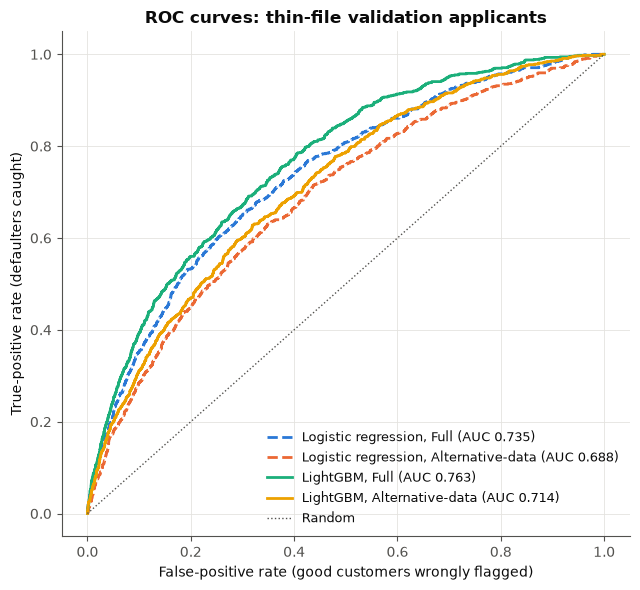

In [45]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for color, key in zip(PALETTE, MODEL_ORDER):
    fpr, tpr, _ = roc_curve(y_valid[thin_valid], valid_scores[key][thin_valid])
    ax.plot(fpr, tpr, color=color, linestyle="-" if key[0] == "LightGBM" else "--",
            label=f"{key[0]}, {key[1]} (AUC {valid_metrics_thin.loc[key, 'roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=INK_MUTED, linewidth=1, linestyle=":", label="Random")
ax.set_xlabel("False-positive rate (good customers wrongly flagged)")
ax.set_ylabel("True-positive rate (defaulters caught)")
ax.set_title("ROC curves: thin-file validation applicants")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Takeaway:** On thin-file applicants the alternative-data LightGBM (AUC 0.714) clearly beats the alternative-data logistic regression (0.688). The full model scores higher (0.763), helped by EXT_SOURCE_1/2, which exist for many thin-file applicants in this dataset. EXT_SOURCE_3 is missing for 97% of them, consistent with these being bureau-derived scores that a real Indian new-to-credit applicant would not have.

## 12. Calibration

**Why it matters:** the business analysis multiplies each applicant's PD by the loan amount and LGD to get expected loss, and compares PD with the break-even PD to decide. A model can rank applicants perfectly (high AUC) and still say "5%" for a group that actually defaults 10% of the time. That would understate losses, misprice the product, and push the approval threshold into loss-making territory. We need **PD = observed default rate**, not just a good ranking.

### 12.1 Reliability curves before calibration (LightGBM)
Applicants are grouped into ten equal-sized bins by predicted PD. A well-calibrated model sits on the diagonal.

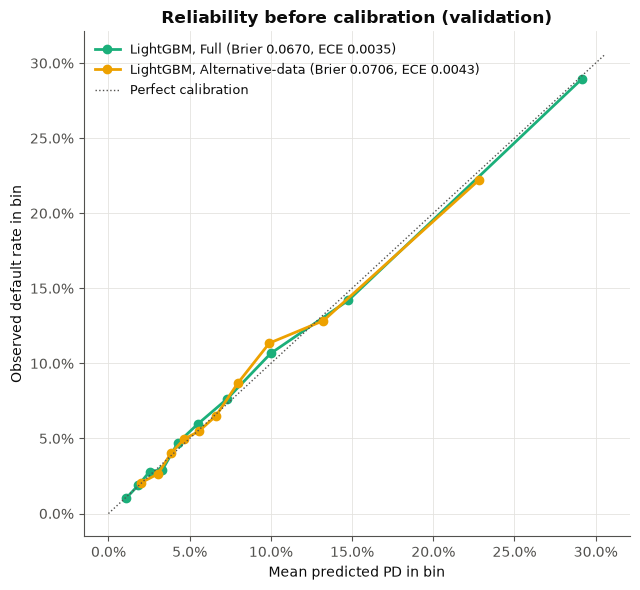

In [46]:
def plot_reliability(prob_dict, y, title, n_bins=10):
    """Reliability diagram: mean predicted PD vs. observed default rate in equal-frequency bins."""
    fig, ax = plt.subplots(figsize=(6.5, 6))
    upper = 0
    for color, (label, p) in zip(PALETTE[2:], prob_dict.items()):
        frame = pd.DataFrame({"y": y, "p": p})
        frame["bin"] = pd.qcut(frame["p"].rank(method="first"), n_bins, labels=False)
        agg = frame.groupby("bin").agg(pred=("p", "mean"), obs=("y", "mean"))
        upper = max(upper, agg.max().max())
        ax.plot(agg["pred"], agg["obs"], marker="o", markersize=6, color=color,
                label=f"{label} (Brier {brier_score_loss(y, p):.4f}, ECE {expected_calibration_error(y, p):.4f})")
    ax.plot([0, upper * 1.05], [0, upper * 1.05], color=INK_MUTED, linestyle=":", linewidth=1, label="Perfect calibration")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("Mean predicted PD in bin")
    ax.set_ylabel("Observed default rate in bin")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()


plot_reliability({f"LightGBM, {fs}": valid_scores[("LightGBM", fs)] for fs in FEATURE_SETS}, y_valid,
                 "Reliability before calibration (validation)")

### 12.2 Isotonic calibration, fitted out of fold
Isotonic regression maps raw scores to PDs monotonically, so the ranking and AUC are essentially unchanged. We fit it with 5-fold cross-fitting on the validation set: each validation applicant's calibrated PD comes from a calibrator that never saw that applicant. A final calibrator fitted on all validation rows is kept for the test set. The calibrated version is used only if it actually lowers the Brier score.

In [47]:
calibrators, pd_valid, calibration_rows = {}, {}, []
for fs in FEATURE_SETS:
    raw = valid_scores[("LightGBM", fs)]
    oof, calibrators[fs] = crossfit_isotonic(raw, y_valid, seed=RANDOM_SEED)
    brier_raw, brier_cal = brier_score_loss(y_valid, raw), brier_score_loss(y_valid, oof)
    use_calibrated = brier_cal < brier_raw
    pd_valid[fs] = oof if use_calibrated else raw
    if not use_calibrated:
        calibrators[fs] = None
    calibration_rows.append({"feature_set": fs, "brier_raw": brier_raw, "brier_calibrated": brier_cal,
                             "ece_raw": expected_calibration_error(y_valid, raw),
                             "ece_calibrated": expected_calibration_error(y_valid, oof),
                             "auc_raw": roc_auc_score(y_valid, raw), "auc_calibrated": roc_auc_score(y_valid, oof),
                             "use_calibrated": use_calibrated})
calibration_table = pd.DataFrame(calibration_rows).set_index("feature_set")
display(calibration_table.style.format({c: "{:.4f}" for c in calibration_table.columns if c != "use_calibrated"}))

,brier_raw,brier_calibrated,ece_raw,ece_calibrated,auc_raw,auc_calibrated,use_calibrated
feature_set,,,,,,,
Full,0.0670,0.0670,0.0035,0.0017,0.7695,0.7677,False
Alternative-data,0.0706,0.0706,0.0043,0.0013,0.7068,0.7053,False


### 12.3 Reliability after calibration
These are the PDs that feed the business analysis.

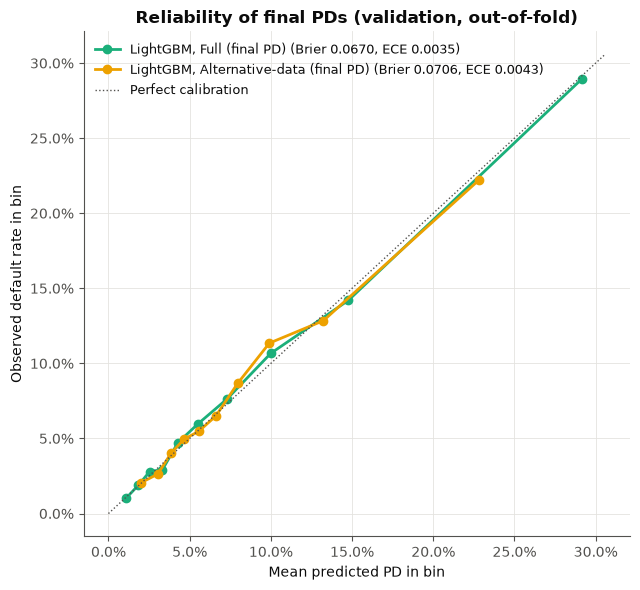

In [48]:
plot_reliability({f"LightGBM, {fs} (final PD)": pd_valid[fs] for fs in FEATURE_SETS}, y_valid,
                 "Reliability of final PDs (validation, out-of-fold)")

**Takeaway:** LightGBM trained without class re-weighting is already well calibrated (ECE â‰ˆ 0.004). Out-of-fold isotonic calibration did not lower the Brier score, so the raw probabilities are kept as the final PDs; the safeguard stays in the pipeline for future retrains.

## 13. Explainability (SHAP): what drives the alternative-data model?

### 13.1 SHAP values on a validation sample
LightGBM computes exact TreeSHAP contributions natively (`pred_contrib=True`), which is fast and handles categorical splits correctly. The values are in **log-odds**: positive values push towards default. We explain a random sample of validation applicants to keep the runtime low.

In [49]:
shap_rows = rng.choice(len(valid_df), size=min(SHAP_SAMPLE_SIZE, len(valid_df)), replace=False)
X_shap = X_valid_lgb.iloc[shap_rows][FEATURES_ALT]
booster_alt = lgb_models["Alternative-data"]
contrib = booster_alt.predict(X_shap, num_iteration=booster_alt.best_iteration, pred_contrib=True)
shap_values, shap_base = contrib[:, :-1], contrib[0, -1]

# numeric view of the features for colouring the summary plot (categories -> integer codes)
X_shap_numeric = X_shap.copy()
for c in X_shap_numeric.columns.intersection(CAT_COLS):
    X_shap_numeric[c] = X_shap_numeric[c].cat.codes.replace(-1, np.nan)
print(f"SHAP matrix: {shap_values.shape}, base value (log-odds) = {shap_base:.3f}")

SHAP matrix: (3000, 121), base value (log-odds) = -2.682


### 13.2 SHAP summary plot
Each dot is one applicant. Horizontal position is the feature's push towards (right) or away from (left) default. Colour is the feature's value, from low (blue) to high (red).

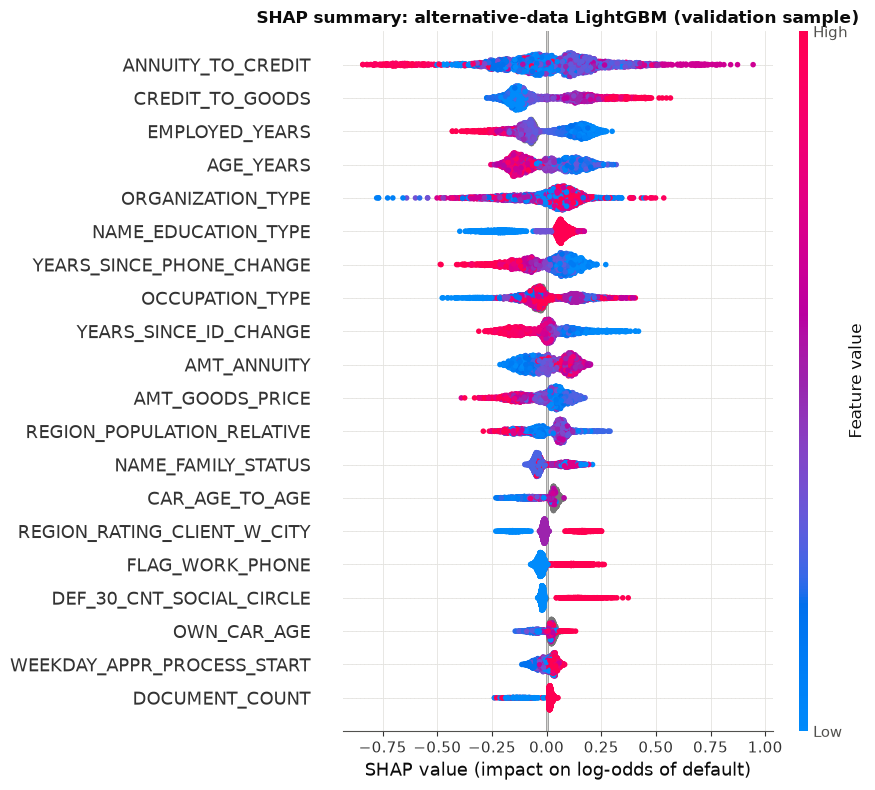

In [50]:
shap.summary_plot(shap_values, X_shap_numeric, max_display=20, show=False, plot_size=(9, 8))
plt.title("SHAP summary: alternative-data LightGBM (validation sample)")
plt.xlabel("SHAP value (impact on log-odds of default)")
plt.tight_layout()
plt.show()

### 13.3 Mean |SHAP| ranking with signal type
Features are grouped into broad signal families so the business can see which *kinds* of alternative data carry weight.

In [51]:
def signal_family(col):
    """Map a feature name to a broad alternative-data signal family (for reporting only)."""
    if col in {"AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "CREDIT_TO_GOODS", "ANNUITY_TO_CREDIT", "NAME_CONTRACT_TYPE"}:
        return "Loan structure"
    if col in {"AMT_INCOME_TOTAL", "CREDIT_TO_INCOME", "ANNUITY_TO_INCOME", "INCOME_PER_PERSON"}:
        return "Income & affordability"
    if "EMPLOY" in col or col in {"ORGANIZATION_TYPE", "OCCUPATION_TYPE", "NAME_INCOME_TYPE"}:
        return "Employment"
    if col.startswith(("FLAG_DOCUMENT", "DOCUMENT_COUNT", "FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE",
                       "FLAG_CONT_MOBILE", "FLAG_PHONE", "FLAG_EMAIL", "CONTACT_COUNT", "YEARS_SINCE")):
        return "Documents, contact & identity stability"
    if col.startswith(("REGION", "REG_", "LIVE_", "ADDRESS")):
        return "Region & address"
    if "SOCIAL_CIRCLE" in col:
        return "Social circle"
    if col in {"AGE_YEARS", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "CNT_CHILDREN", "CNT_FAM_MEMBERS"}:
        return "Demographics & education"
    if col.startswith(("FLAG_OWN", "OWN_CAR", "CAR_AGE", "NAME_HOUSING")) or col.endswith(("_AVG", "_MODE", "_MEDI")):
        return "Assets & housing"
    return "Other application data"


shap_importance = pd.DataFrame({"feature": FEATURES_ALT, "mean_abs_shap": np.abs(shap_values).mean(axis=0)})
shap_importance["signal_family"] = shap_importance["feature"].map(signal_family)
shap_importance = shap_importance.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
family_importance = (shap_importance.groupby("signal_family")["mean_abs_shap"].sum()
                     .sort_values(ascending=False).to_frame("total_mean_abs_shap"))
family_importance["share"] = family_importance["total_mean_abs_shap"] / family_importance["total_mean_abs_shap"].sum()
display(shap_importance.head(15).style.format({"mean_abs_shap": "{:.4f}"}))
display(family_importance.style.format({"total_mean_abs_shap": "{:.4f}", "share": "{:.1%}"}))

,feature,mean_abs_shap,signal_family
0,ANNUITY_TO_CREDIT,0.1911,Loan structure
1,CREDIT_TO_GOODS,0.1520,Loan structure
2,EMPLOYED_YEARS,0.1356,Employment
3,AGE_YEARS,0.1140,Demographics & education
4,ORGANIZATION_TYPE,0.1086,Employment
5,NAME_EDUCATION_TYPE,0.1074,Demographics & education
6,YEARS_SINCE_PHONE_CHANGE,0.1035,"Documents, contact & identity stability"
7,OCCUPATION_TYPE,0.0983,Employment
8,YEARS_SINCE_ID_CHANGE,0.0925,"Documents, contact & identity stability"
9,AMT_ANNUITY,0.0836,Loan structure


,total_mean_abs_shap,share
signal_family,,
Loan structure,0.5478,23.8%
Employment,0.3931,17.0%
Assets & housing,0.3617,15.7%
"Documents, contact & identity stability",0.3418,14.8%
Demographics & education,0.2847,12.3%
Region & address,0.1872,8.1%
Income & affordability,0.0697,3.0%
Social circle,0.0614,2.7%
Other application data,0.0584,2.5%


**Takeaway:** Loan structure dominates: ANNUITY_TO_CREDIT (a proxy for tenor) and CREDIT_TO_GOODS (financing beyond the goods' price) rank first and second. Next come employment tenure, age, organisation and occupation type, education, and identity/phone stability (years since the phone number or ID document changed). These are all data an e-commerce lender can collect or verify at checkout. Income itself carries surprisingly little weight (3% of total |SHAP|).

### 13.4 Individual explanations for three thin-file applicants
From the SHAP sample we take the thin-file applicant with the **lowest** predicted risk (a confident approve), the one at the **median** (borderline), and the one with the **highest** risk (a confident decline). These waterfall charts are the basis of **adverse-action reasons**: the top positive contributions explain a decline to the customer.

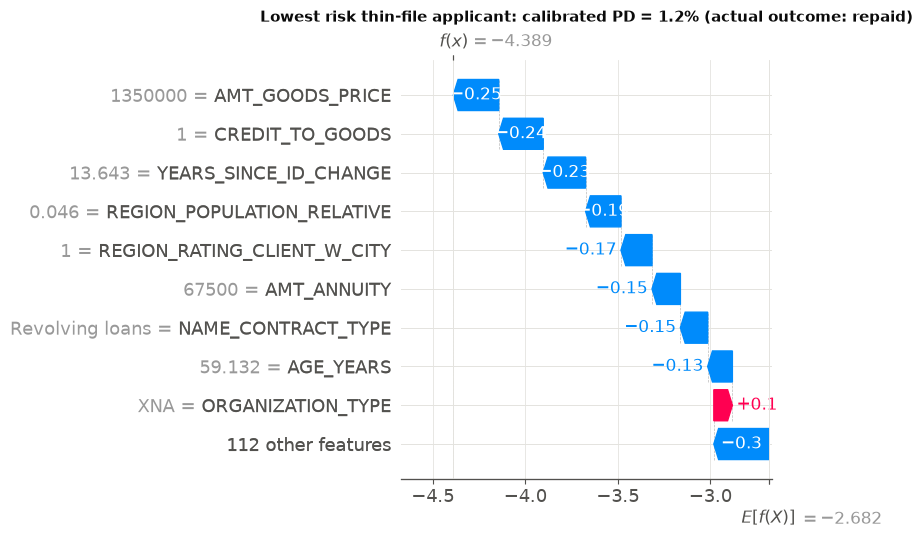

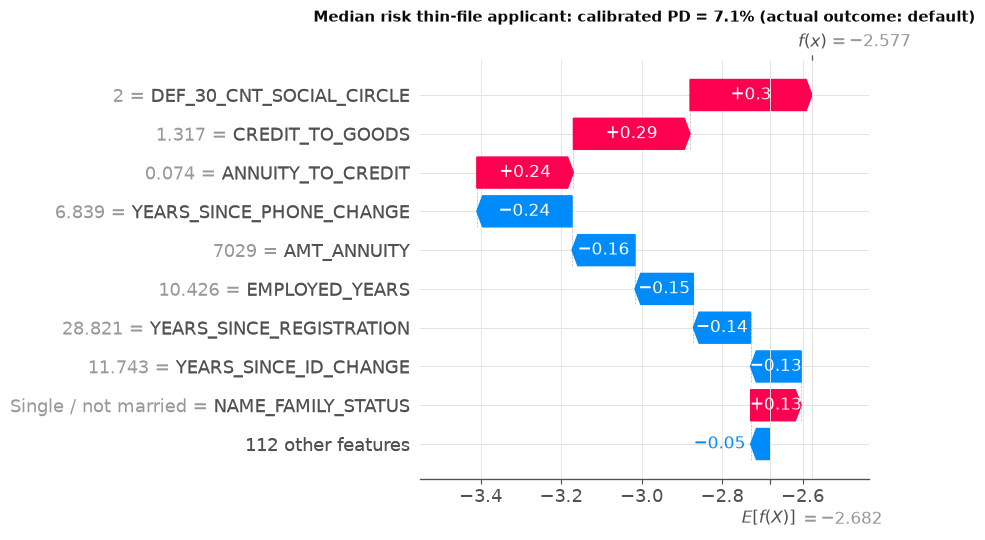

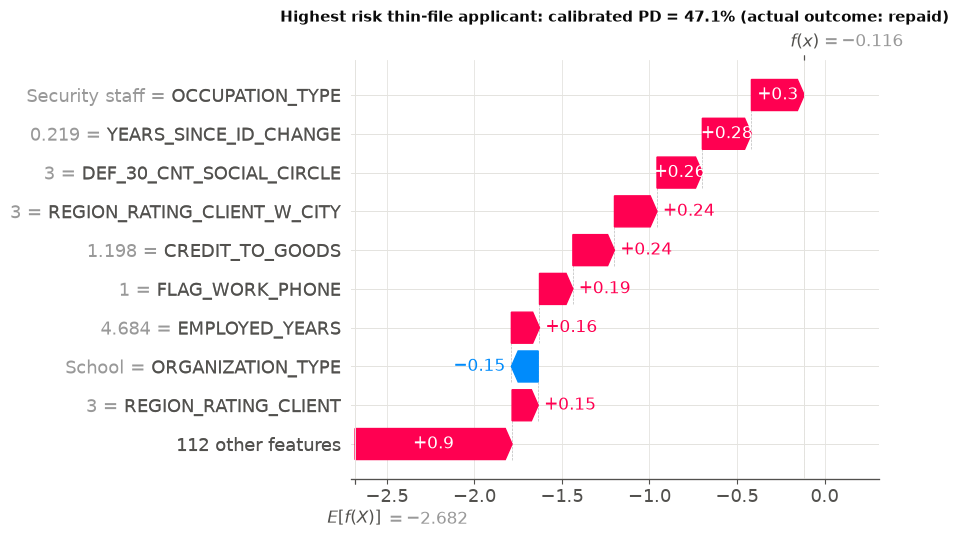

In [52]:
thin_in_sample = np.where(thin_valid[shap_rows])[0]
raw_logodds = shap_values.sum(axis=1) + shap_base
ordered = thin_in_sample[np.argsort(raw_logodds[thin_in_sample])]
cases = {"Lowest risk": ordered[0], "Median risk": ordered[len(ordered) // 2], "Highest risk": ordered[-1]}

for label, i in cases.items():
    calibrated_pd = pd_valid["Alternative-data"][shap_rows[i]]
    explanation = shap.Explanation(values=shap_values[i], base_values=shap_base,
                                   data=X_shap.iloc[i].astype(object).values, feature_names=FEATURES_ALT)
    shap.plots.waterfall(explanation, max_display=10, show=False)
    plt.title(f"{label} thin-file applicant: calibrated PD = {calibrated_pd:.1%} "
              f"(actual outcome: {'default' if y_valid[shap_rows[i]] else 'repaid'})", fontsize=11, pad=28)
    plt.gcf().set_size_inches(9, 5.5)
    plt.tight_layout()
    plt.show()

## 14. Business decision analysis

The policy is **"approve if calibrated PD ≤ threshold"**, evaluated on the validation set for thresholds from 0 to 1 in steps of 0.005. The **alternative-data LightGBM** is the deployable model for this product, because it scores every applicant whether or not they have a credit history. The full model is shown alongside as the "if we had bureau data for everyone" benchmark.

### 14.1 Profit curves

In [53]:
curves = {fs: profit_curve(y_valid, pd_valid[fs]) for fs in FEATURE_SETS}
curve_alt, curve_full = curves["Alternative-data"], curves["Full"]
print(f"Computed {len(THRESHOLDS)} thresholds for each model")

Computed 201 thresholds for each model


### 14.2 Policy table: alternative-data model
Selected thresholds. Money is in INR per 1,000 applicants.

In [54]:
MONEY_FORMAT = {"threshold": "{:.3f}", "n_approved": "{:,.0f}", "approval_rate": "{:.1%}", "exp_default_rate_approved": "{:.2%}",
                "default_rate_approved": "{:.2%}", "expected_loss_rate": "{:.2%}", "expected_revenue": "₹{:,.0f}",
                "expected_loss": "₹{:,.0f}", "funding_cost": "₹{:,.0f}", "expected_profit": "₹{:,.0f}", "realised_profit": "₹{:,.0f}"}
show_thresholds = np.round(np.r_[np.arange(0.025, 0.301, 0.025), 0.4, 0.5, 1.0], 3)
display(curve_alt[curve_alt["threshold"].isin(show_thresholds)].set_index("threshold").style.format(MONEY_FORMAT))

,n_approved,approval_rate,exp_default_rate_approved,default_rate_approved,expected_loss_rate,expected_revenue,expected_loss,funding_cost,expected_profit,realised_profit
threshold,,,,,,,,,,
0.025000,"5,457",8.9%,1.94%,1.98%,1.65%,"₹348,041","₹36,522","₹110,911","₹200,607","₹199,664"
0.050000,"23,965",39.0%,3.35%,3.36%,2.85%,"₹1,506,479","₹277,152","₹487,078","₹742,249","₹740,663"
0.075000,"38,134",62.0%,4.39%,4.39%,3.73%,"₹2,371,271","₹578,577","₹775,056","₹1,017,637","₹1,018,264"
0.100000,"46,465",75.6%,5.15%,5.34%,4.38%,"₹2,866,341","₹827,020","₹944,380","₹1,094,942","₹1,059,868"
0.125000,"51,413",83.6%,5.73%,5.94%,4.87%,"₹3,152,287","₹1,017,552","₹1,044,946","₹1,089,789","₹1,045,043"
0.150000,"54,551",88.7%,6.18%,6.36%,5.26%,"₹3,328,492","₹1,165,698","₹1,108,724","₹1,054,070","₹1,013,743"
0.175000,"56,627",92.1%,6.55%,6.77%,5.57%,"₹3,441,702","₹1,281,564","₹1,150,918","₹1,009,219","₹957,538"
0.200000,"57,998",94.3%,6.84%,7.03%,5.81%,"₹3,514,240","₹1,369,907","₹1,178,783","₹965,551","₹918,665"
0.225000,"59,044",96.0%,7.09%,7.26%,6.03%,"₹3,567,856","₹1,446,484","₹1,200,042","₹921,329","₹880,040"


### 14.3 Approval rate vs. expected loss
The trade-off the credit committee actually argues about: each point is a threshold. Moving right approves more people and costs more in expected losses. A better model sits **lower** at every approval rate.

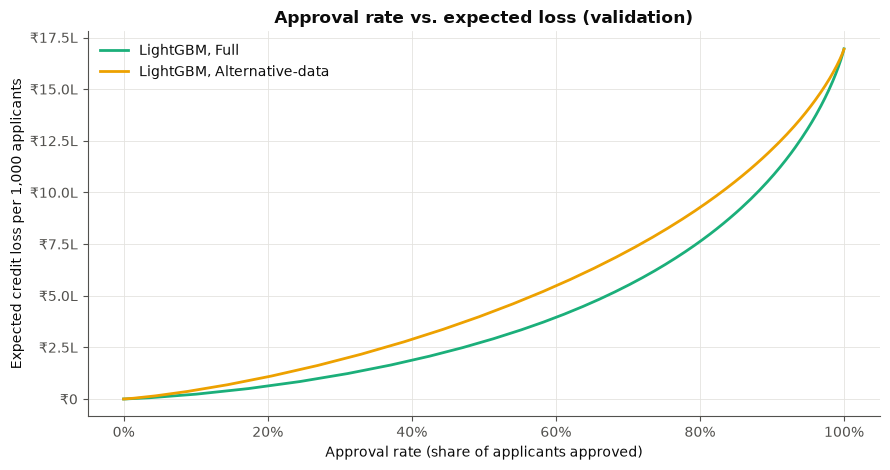

In [55]:
fig, ax = plt.subplots()
for color, fs in zip(PALETTE[2:], FEATURE_SETS):
    c = curves[fs]
    ax.plot(c["approval_rate"], c["expected_loss"], color=color, label=f"LightGBM, {fs}")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(FuncFormatter(inr))
ax.set_xlabel("Approval rate (share of applicants approved)")
ax.set_ylabel(f"Expected credit loss per {PER_N_APPLICANTS:,} applicants")
ax.set_title("Approval rate vs. expected loss (validation)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 14.4 Choose thresholds: profit-maximising and conservative
* **Profit-maximising**: the highest expected profit.
* **Conservative**: the lowest threshold that still earns at least 90% of the maximum. It approves fewer people and carries lower losses, which makes it a sensible **launch setting** for a new product whose economics are still assumptions.

With calibrated PDs, the profit-maximising threshold should land close to the theoretical break-even PD.

In [56]:
policy_rows = []
for fs in FEATURE_SETS:
    best, conservative = pick_thresholds(curves[fs])
    for policy, row in {"Profit-maximising": best, "Conservative (≥90% of max profit)": conservative}.items():
        policy_rows.append({"model": f"LightGBM, {fs}", "policy": policy, **row.to_dict()})
policy_table = pd.DataFrame(policy_rows).set_index(["model", "policy"])
display(policy_table.style.format(MONEY_FORMAT))

OPT_ALT = policy_table.loc[("LightGBM, Alternative-data", "Profit-maximising")]
CONS_ALT = policy_table.loc[("LightGBM, Alternative-data", "Conservative (≥90% of max profit)")]
CHOSEN_THRESHOLD = float(CONS_ALT["threshold"])
CHOSEN_POLICY = "Alternative-data LightGBM, conservative threshold"
print(f"Break-even PD (theory): {BREAKEVEN_PD:.3f} | profit-maximising threshold (alt model): {OPT_ALT['threshold']:.3f}")
print(f"Chosen launch policy: {CHOSEN_POLICY} -> approve if PD <= {CHOSEN_THRESHOLD:.3f}")

Break-even PD (theory): 0.109 | profit-maximising threshold (alt model): 0.110
Chosen launch policy: Alternative-data LightGBM, conservative threshold -> approve if PD <= 0.075


### 14.5 Threshold vs. expected profit
Solid lines are expected profit (from the PDs); the dashed line is the profit *realised* on validation outcomes for the alternative-data model. Markers show the two chosen thresholds.

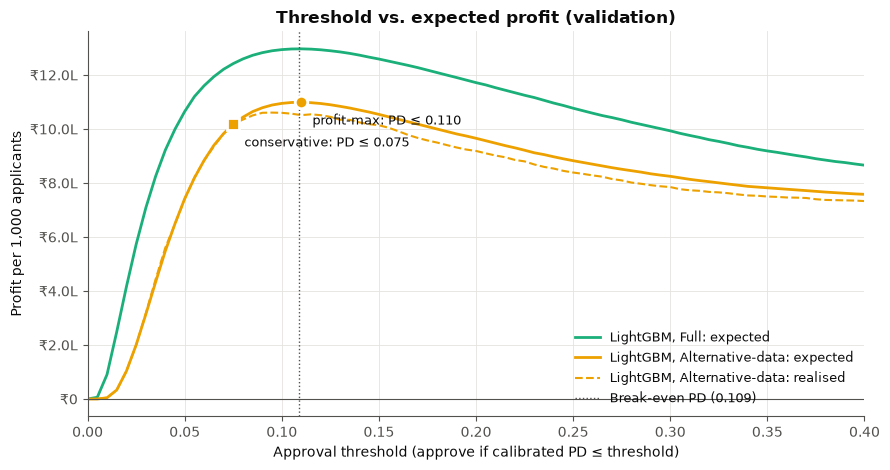

In [57]:
fig, ax = plt.subplots()
for color, fs in zip(PALETTE[2:], FEATURE_SETS):
    ax.plot(curves[fs]["threshold"], curves[fs]["expected_profit"], color=color, label=f"LightGBM, {fs}: expected")
ax.plot(curve_alt["threshold"], curve_alt["realised_profit"], color=PALETTE[3], linestyle="--", linewidth=1.5,
        label="LightGBM, Alternative-data: realised")
ax.axvline(BREAKEVEN_PD, color=INK_MUTED, linestyle=":", linewidth=1, label=f"Break-even PD ({BREAKEVEN_PD:.3f})")
ax.axhline(0, color=INK_MUTED, linewidth=0.8)
for row, marker, name in [(OPT_ALT, "o", "profit-max"), (CONS_ALT, "s", "conservative")]:
    ax.plot(row["threshold"], row["expected_profit"], marker=marker, markersize=9, color=PALETTE[3],
            markeredgecolor="white", markeredgewidth=2, linestyle="none")
    ax.annotate(f"{name}: PD ≤ {row['threshold']:.3f}", (row["threshold"], row["expected_profit"]),
                textcoords="offset points", xytext=(8, -16), fontsize=9, color=INK)
ax.set_xlim(0, 0.4)
ax.yaxis.set_major_formatter(FuncFormatter(inr))
ax.set_xlabel("Approval threshold (approve if calibrated PD ≤ threshold)")
ax.set_ylabel(f"Profit per {PER_N_APPLICANTS:,} applicants")
ax.set_title("Threshold vs. expected profit (validation)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Takeaway:** Expected and realised profit track each other closely, which confirms the calibrated PDs. The alternative-data model's profit peaks at a 0.110 cut-off, right at the 0.109 break-even PD. The conservative 0.075 cut-off keeps 93% of that profit while approving 62% instead of 79% of applicants.

### 14.6 The thin-file opportunity vs. the naive rule
**Naive rule:** approve every applicant with a bureau history and reject every thin-file applicant. Its realised default rate among approved customers is the loss level the business already tolerates.

**Question:** using the alternative-data model on thin-file applicants only, how many can we approve while keeping *their* default rate (and so their loss rate, since LGD and loan size are fixed) **at or below** the naive book's rate? Realised validation outcomes are used on both sides, so the comparison is like for like.

In [58]:
naive_default_rate = y_valid[~thin_valid].mean()
naive_loss_rate = naive_default_rate * LGD

thin_curves = {fs: profit_curve(y_valid[thin_valid], pd_valid[fs][thin_valid]) for fs in FEATURE_SETS}
thin_rows = []
for fs, tc in thin_curves.items():
    ok = tc[(tc["n_approved"] > 0) & (tc["default_rate_approved"] <= naive_default_rate)]
    best = ok.loc[ok["n_approved"].idxmax()]
    thin_rows.append({"model": f"LightGBM, {fs}", "max_threshold_at_naive_loss": best["threshold"],
                      "thin_file_approved": int(best["n_approved"]), "share_of_thin_file_approved": best["approval_rate"],
                      "default_rate_of_approved": best["default_rate_approved"],
                      "loss_rate_of_approved": best["default_rate_approved"] * LGD,
                      "per_100k_applicants": best["n_approved"] / len(valid_df) * 100_000,
                      "realised_profit_per_1000_thin": best["realised_profit"]})
thin_opportunity = pd.DataFrame(thin_rows).set_index("model")

print(f"Validation thin-file applicants: {thin_valid.sum():,} of {len(valid_df):,}")
print(f"Naive rule: approves 0 thin-file applicants; default rate of its approved book = {naive_default_rate:.2%} "
      f"(loss rate {naive_loss_rate:.2%} of principal)")
display(thin_opportunity.style.format({"max_threshold_at_naive_loss": "{:.3f}", "thin_file_approved": "{:,}",
                                       "share_of_thin_file_approved": "{:.1%}", "default_rate_of_approved": "{:.2%}",
                                       "loss_rate_of_approved": "{:.2%}", "per_100k_applicants": "{:,.0f}",
                                       "realised_profit_per_1000_thin": "₹{:,.0f}"}))
THIN_OPP_ALT = thin_opportunity.loc["LightGBM, Alternative-data"]

Validation thin-file applicants: 8,803 of 61,502
Naive rule: approves 0 thin-file applicants; default rate of its approved book = 7.73% (loss rate 6.57% of principal)


,max_threshold_at_naive_loss,thin_file_approved,share_of_thin_file_approved,default_rate_of_approved,loss_rate_of_approved,per_100k_applicants,realised_profit_per_1000_thin
model,,,,,,,
"LightGBM, Full",0.230,"7,974",90.6%,7.70%,6.55%,"12,965","₹729,865"
"LightGBM, Alternative-data",0.160,"7,532",85.6%,7.66%,6.51%,"12,247","₹697,915"


### 14.7 Thin-file approval rate vs. default rate among approved
Each curve traces the thin-file approval rate against the default rate of those approved, as the threshold loosens. The dashed line is the naive book's default rate. Everything under it is "free" growth at no extra loss rate.

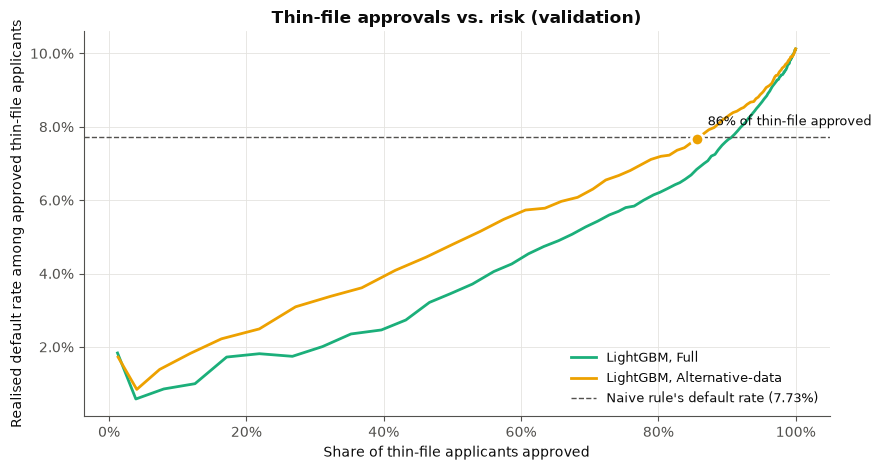

In [59]:
fig, ax = plt.subplots()
for color, fs in zip(PALETTE[2:], FEATURE_SETS):
    tc = thin_curves[fs][thin_curves[fs]["n_approved"] >= 50]
    ax.plot(tc["approval_rate"], tc["default_rate_approved"], color=color, label=f"LightGBM, {fs}")
ax.axhline(naive_default_rate, color=INK_MUTED, linestyle="--", linewidth=1,
           label=f"Naive rule's default rate ({naive_default_rate:.2%})")
ax.plot(THIN_OPP_ALT["share_of_thin_file_approved"], THIN_OPP_ALT["default_rate_of_approved"], marker="o", markersize=9,
        color=PALETTE[3], markeredgecolor="white", markeredgewidth=2, linestyle="none")
ax.annotate(f"{THIN_OPP_ALT['share_of_thin_file_approved']:.0%} of thin-file approved",
            (THIN_OPP_ALT["share_of_thin_file_approved"], THIN_OPP_ALT["default_rate_of_approved"]),
            textcoords="offset points", xytext=(8, 10), fontsize=9)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Share of thin-file applicants approved")
ax.set_ylabel("Realised default rate among approved thin-file applicants")
ax.set_title("Thin-file approvals vs. risk (validation)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Takeaway:** Under the naive rule every thin-file applicant is rejected. The alternative-data model can approve about 86% of them (7,532 of 8,803 on validation) at a 7.66% default rate, no worse than the 7.73% of the naive book. That is roughly 12,000 additional approved customers per 100,000 applications.

## 15. Sensitivity analysis: how fragile is the threshold?

The business assumptions are the least certain inputs. We re-run the profit analysis for the alternative-data model on a grid of **LGD** (60%–100%) × **margin** (10%–25% over the tenor), holding loan size and cost of funds fixed, and record where the optimum lands.

### 15.1 Re-run the profit analysis on the grid

In [60]:
LGD_GRID = [0.60, 0.70, 0.80, 0.85, 0.90, 1.00]
MARGIN_GRID = [0.10, 0.13, 0.16, 0.20, 0.25]
sens_rows = []
for lgd_value in LGD_GRID:
    for margin_value in MARGIN_GRID:
        c = profit_curve(y_valid, pd_valid["Alternative-data"], lgd=lgd_value, margin=margin_value)
        best, conservative = pick_thresholds(c)
        sens_rows.append({"LGD": lgd_value, "margin": margin_value,
                          "breakeven_pd": (margin_value - COST_OF_FUNDS_RATE) / (margin_value + lgd_value),
                          "optimal_threshold": best["threshold"], "conservative_threshold": conservative["threshold"],
                          "approval_rate_at_optimum": best["approval_rate"], "expected_profit_at_optimum": best["expected_profit"]})
sensitivity = pd.DataFrame(sens_rows)
display(sensitivity.style.format({"LGD": "{:.0%}", "margin": "{:.0%}", "breakeven_pd": "{:.3f}", "optimal_threshold": "{:.3f}",
                                  "conservative_threshold": "{:.3f}", "approval_rate_at_optimum": "{:.1%}",
                                  "expected_profit_at_optimum": "₹{:,.0f}"}))

,LGD,margin,breakeven_pd,optimal_threshold,conservative_threshold,approval_rate_at_optimum,expected_profit_at_optimum
0,60%,10%,0.071,0.070,0.055,58.2%,"₹299,264"
1,60%,13%,0.110,0.110,0.075,79.3%,"₹804,059"
2,60%,16%,0.145,0.145,0.085,87.8%,"₹1,397,379"
3,60%,20%,0.187,0.190,0.100,93.6%,"₹2,248,145"
4,60%,25%,0.235,0.235,0.110,96.5%,"₹3,354,347"
5,70%,10%,0.062,0.065,0.050,54.1%,"₹242,123"
6,70%,13%,0.096,0.095,0.070,73.4%,"₹703,928"
7,70%,16%,0.128,0.130,0.080,84.8%,"₹1,269,454"
8,70%,20%,0.167,0.165,0.095,90.9%,"₹2,096,621"
9,70%,25%,0.211,0.210,0.105,95.0%,"₹3,185,051"


### 15.2 Heatmaps: optimal threshold and approval rate

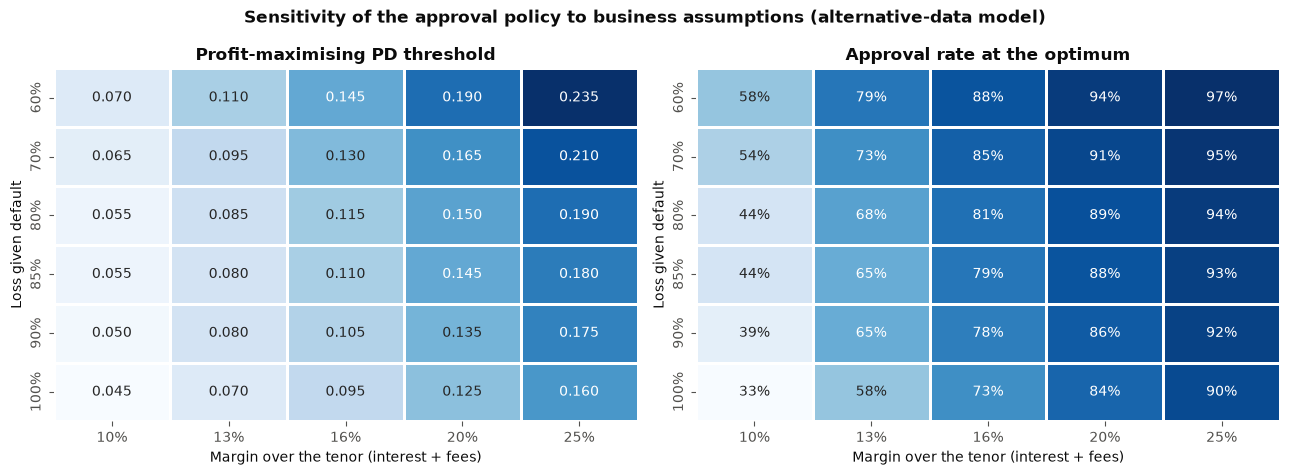

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (col, title, fmt) in zip(axes, [("optimal_threshold", "Profit-maximising PD threshold", ".3f"),
                                         ("approval_rate_at_optimum", "Approval rate at the optimum", ".0%")]):
    grid = sensitivity.pivot(index="LGD", columns="margin", values=col)
    sns.heatmap(grid, annot=True, fmt=fmt, cmap="Blues", cbar=False, linewidths=2, linecolor="white", ax=ax,
                xticklabels=[f"{m:.0%}" for m in grid.columns], yticklabels=[f"{l:.0%}" for l in grid.index])
    ax.set_xlabel("Margin over the tenor (interest + fees)")
    ax.set_ylabel("Loss given default")
    ax.set_title(title)
plt.suptitle("Sensitivity of the approval policy to business assumptions (alternative-data model)", fontweight="bold")
plt.tight_layout()
plt.show()

### 15.3 The optimum tracks the break-even PD
If the PDs are well calibrated, the profit-maximising threshold should equal the break-even PD implied by each set of economics. This plot checks that, and it gives a rule of thumb: **when pricing or collections change, move the cut-off to the new break-even PD.**

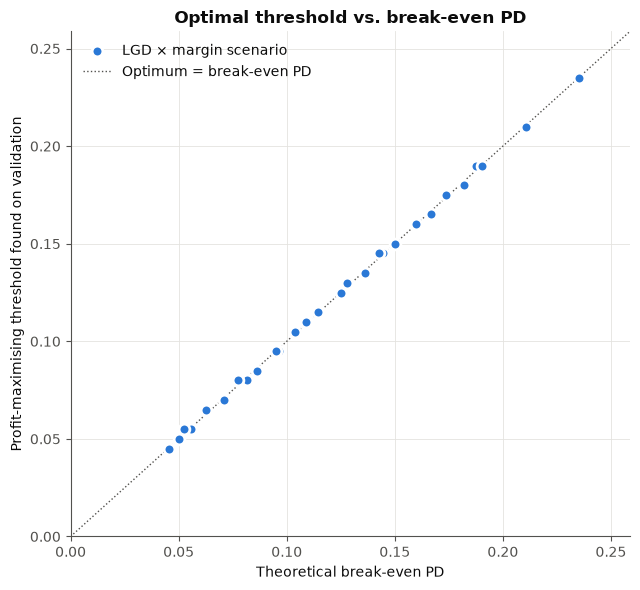

Optimal threshold range across scenarios: 0.045 – 0.235; approval rate range: 33.0% – 96.5%


In [62]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(sensitivity["breakeven_pd"], sensitivity["optimal_threshold"], s=60, color=PALETTE[0],
           edgecolor="white", linewidth=2, zorder=3, label="LGD × margin scenario")
lim = [0, max(sensitivity["breakeven_pd"].max(), sensitivity["optimal_threshold"].max()) * 1.1]
ax.plot(lim, lim, color=INK_MUTED, linestyle=":", linewidth=1, label="Optimum = break-even PD")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Theoretical break-even PD")
ax.set_ylabel("Profit-maximising threshold found on validation")
ax.set_title("Optimal threshold vs. break-even PD")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print(f"Optimal threshold range across scenarios: {sensitivity['optimal_threshold'].min():.3f} – "
      f"{sensitivity['optimal_threshold'].max():.3f}; approval rate range: "
      f"{sensitivity['approval_rate_at_optimum'].min():.1%} – {sensitivity['approval_rate_at_optimum'].max():.1%}")

**Takeaway:** The optimal threshold moves a lot with the economics (0.045 to 0.235, with approval rates from 33% to 97%), but it always sits on the break-even PD. The actionable rule: re-derive the cut-off from margin and LGD instead of re-tuning it by hand. Margin moves the answer more than LGD does across these ranges.

## 16. Segment fairness check at the chosen threshold

Outcomes of the launch policy (alternative-data model, approve if PD ≤ chosen threshold) on the validation set, broken down by **gender** (not a model input), **age band**, **region rating** and **thin-file status**. For each group we compare the approval rate and the default rate of those approved. A large approval gap with *similar* default rates among the approved would suggest the model is stricter on a group than its risk justifies.

In [63]:
approved_valid = pd_valid["Alternative-data"] <= CHOSEN_THRESHOLD
fairness_tables = {col: segment_decision_table(valid_df, col, approved_valid, y_valid)
                   for col in ["CODE_GENDER", "AGE_BAND", "REGION_RATING_CLIENT", "SEGMENT"]}
FAIR_FORMAT = {"applicants": "{:,}", "approval_rate": "{:.1%}", "default_rate_all": "{:.2%}",
               "default_rate_approved": "{:.2%}", "approval_ratio_vs_max": "{:.2f}"}
print(f"Policy: approve if alternative-data PD <= {CHOSEN_THRESHOLD:.3f} | overall approval rate {approved_valid.mean():.1%}")
for col, table in fairness_tables.items():
    display(table.style.format(FAIR_FORMAT).set_caption(col))

Policy: approve if alternative-data PD <= 0.075 | overall approval rate 62.0%


,applicants,approval_rate,default_rate_all,default_rate_approved,approval_ratio_vs_max
CODE_GENDER,,,,,
F,"40,622",66.0%,6.96%,4.00%,1.00
M,"20,878",54.2%,10.23%,5.30%,0.82


,applicants,approval_rate,default_rate_all,default_rate_approved,approval_ratio_vs_max
AGE_BAND,,,,,
<25,"2,473",28.8%,11.77%,6.32%,0.35
25-34,"14,482",43.6%,10.85%,5.16%,0.53
35-44,"16,833",60.9%,8.41%,4.55%,0.74
45-54,"13,935",67.8%,6.97%,4.17%,0.82
55+,"13,779",82.7%,5.20%,3.88%,1.00


,applicants,approval_rate,default_rate_all,default_rate_approved,approval_ratio_vs_max
REGION_RATING_CLIENT,,,,,
1,"6,388",83.1%,4.57%,3.35%,1.00
2,"45,530",62.8%,7.95%,4.52%,0.76
3,"9,584",44.0%,10.98%,4.81%,0.53


,applicants,approval_rate,default_rate_all,default_rate_approved,approval_ratio_vs_max
SEGMENT,,,,,
Has bureau history,"52,699",63.3%,7.73%,4.28%,1.00
Thin-file (no bureau history),"8,803",54.1%,10.12%,5.15%,0.85


### 16.1 Approval rates by segment

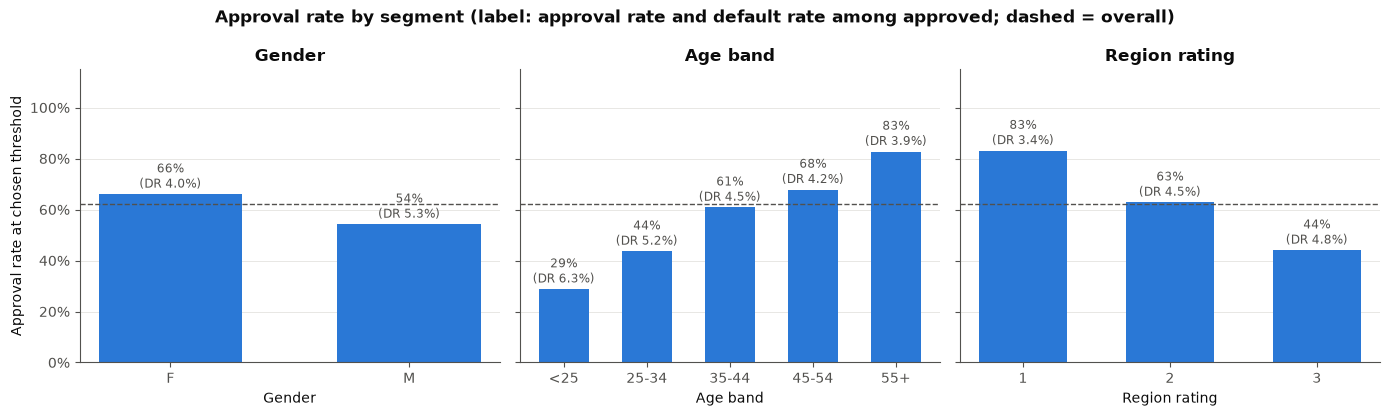

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (col, title) in zip(axes, [("CODE_GENDER", "Gender"), ("AGE_BAND", "Age band"), ("REGION_RATING_CLIENT", "Region rating")]):
    t = fairness_tables[col]
    ax.bar(t.index.astype(str), t["approval_rate"], width=0.6, color=PALETTE[0])
    for i, (rate, dr) in enumerate(zip(t["approval_rate"], t["default_rate_approved"])):
        ax.text(i, rate + 0.01, f"{rate:.0%}\n(DR {dr:.1%})", ha="center", va="bottom", fontsize=8.5, color=INK_MUTED)
    ax.axhline(approved_valid.mean(), color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_ylim(0, 1.15)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    ax.set_xlabel(title)
axes[0].set_ylabel("Approval rate at chosen threshold")
plt.suptitle("Approval rate by segment (label: approval rate and default rate among approved; dashed = overall)",
             fontweight="bold")
plt.tight_layout()
plt.show()

**Takeaway:** Approval rates differ sharply by age (29% for under-25s vs. 83% for 55+) and region rating (83% vs. 44%), and less by gender (F 66% vs. M 54%). The less-approved groups still show *higher* default rates among the customers who were approved (6.3% for approved under-25s vs. 3.9% for 55+). So the model is not stricter than their measured risk justifies; it reflects genuine risk differences. The under-25 gap (approval ratio 0.35) is still a product-design problem to solve: this is the core first-time-borrower segment.

**Responsible-lending considerations**

* **Protected attributes stay out of the model.** Gender is excluded from the inputs and used only for monitoring. Proxies can still leak in (occupation, income type, age), which is why outcome audits like this one are required, not optional.
* **Age is a legitimate risk driver but a sensitive one.** Younger applicants are both riskier and the core first-time-borrower segment. A policy that simply declines the young would defeat the product's purpose. Options include lower starting limits with limit increases after on-time repayment, rather than outright declines.
* **Explainability.** SHAP reasons (section 13) can drive clear decline explanations, consistent with the transparency expectations in Indian digital-lending guidance (e.g. the RBI's Digital Lending Guidelines and the Fair Practices Code).
* **Region rating** may proxy for socio-economic status. It deserves ongoing monitoring for disparate impact.
* The 0.8 approval-ratio screen is a common heuristic, not an Indian legal standard. It flags groups for review, not for automatic action.

## 17. Final evaluation on the held-out test set

Everything is now frozen: models, calibrators, and the chosen threshold. The test set is scored **once**.

### 17.1 Score the test set
LightGBM scores pass through the final isotonic calibrators fitted on the validation set.

In [65]:
test_scores = {key: predict_model(*key, test_df, X_test_lgb) for key in MODEL_ORDER}
pd_test = {fs: (calibrators[fs].predict(test_scores[("LightGBM", fs)]) if calibrators[fs] is not None
                else test_scores[("LightGBM", fs)]) for fs in FEATURE_SETS}
print(f"Test applicants: {len(test_df):,} (thin-file: {thin_test.sum():,})")

Test applicants: 61,503 (thin-file: 8,804)


### 17.2 Ranking metrics on the test set: all applicants and thin-file

In [66]:
test_metrics_all = metrics_table(test_scores, y_test)
test_metrics_thin = metrics_table(test_scores, y_test, thin_test)
display(test_metrics_all.style.format(METRIC_FORMAT).set_caption("Test: all applicants"))
display(test_metrics_thin.style.format(METRIC_FORMAT).set_caption("Test: thin-file applicants"))

### 17.3 Calibration on the test set

In [67]:
test_calibration = pd.DataFrame({fs: {"brier": brier_score_loss(y_test, pd_test[fs]),
                                      "ece": expected_calibration_error(y_test, pd_test[fs]),
                                      "mean_predicted_pd": pd_test[fs].mean(), "observed_default_rate": y_test.mean()}
                                 for fs in FEATURE_SETS}).T
display(test_calibration.style.format("{:.4f}"))

,brier,ece,mean_predicted_pd,observed_default_rate
Full,0.0671,0.0035,0.0804,0.0807
Alternative-data,0.0704,0.0023,0.0802,0.0807


### 17.4 The launch policy on the test set
The chosen policy is applied unchanged. We compare its realised test outcomes with what the validation analysis promised, and repeat the thin-file vs. naive-rule comparison.

In [68]:
test_curve = profit_curve(y_test, pd_test["Alternative-data"], thresholds=np.array([CHOSEN_THRESHOLD]))
test_policy = test_curve.iloc[0]
approved_test = pd_test["Alternative-data"] <= CHOSEN_THRESHOLD
naive_default_rate_test = y_test[~thin_test].mean()
thin_approved_test = approved_test & thin_test

policy_check = pd.DataFrame({
    "validation (expected)": {"approval_rate": CONS_ALT["approval_rate"], "default_rate_approved": CONS_ALT["exp_default_rate_approved"],
                              "profit_per_1000_applicants": CONS_ALT["expected_profit"]},
    "test (realised)": {"approval_rate": test_policy["approval_rate"], "default_rate_approved": test_policy["default_rate_approved"],
                        "profit_per_1000_applicants": test_policy["realised_profit"]},
})
display(policy_check.style.format(lambda v: f"{v:.2%}" if abs(v) < 1 else f"₹{v:,.0f}"))

TEST_THIN_APPROVAL_RATE = thin_approved_test.sum() / thin_test.sum()
TEST_THIN_DEFAULT_RATE = y_test[thin_approved_test].mean()
print(f"Thin-file applicants approved on test at the chosen threshold: {thin_approved_test.sum():,} of {thin_test.sum():,} "
      f"({TEST_THIN_APPROVAL_RATE:.1%}); their default rate {TEST_THIN_DEFAULT_RATE:.2%} "
      f"vs. naive-rule book {naive_default_rate_test:.2%}")

,validation (expected),test (realised)
approval_rate,62.00%,61.77%
default_rate_approved,4.39%,4.48%
profit_per_1000_applicants,"₹1,017,637","₹999,402"


Thin-file applicants approved on test at the chosen threshold: 4,667 of 8,804 (53.0%); their default rate 5.29% vs. naive-rule book 7.73%


### 17.5 Save the key results
All headline numbers are written to `outputs/results.json`. The README and the conclusions below are filled in from these computed values.

In [69]:
def _clean(obj):
    """Convert numpy/pandas scalars to plain Python types for JSON."""
    if isinstance(obj, dict):
        return {str(k): _clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_clean(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    return obj


def _metrics_records(table):
    return [{"model": m, "feature_set": fs, **row} for (m, fs), row in table.to_dict("index").items()]


results = {
    "assumptions": {"avg_loan_inr": AVG_LOAN_INR, "tenor_months": LOAN_TENOR_MONTHS, "margin_rate": MARGIN_RATE,
                    "cost_of_funds_annual": COST_OF_FUNDS_ANNUAL, "lgd": LGD, "breakeven_pd": BREAKEVEN_PD},
    "data": {"applicants": len(app), "base_default_rate": BASE_DEFAULT_RATE, "thin_share": THIN_SHARE,
             "thin_default_rate": THIN_DEFAULT_RATE, "hist_default_rate": HIST_DEFAULT_RATE,
             "n_features_full": len(FEATURES_FULL), "n_features_alt": len(FEATURES_ALT)},
    "validation_metrics_all": _metrics_records(valid_metrics_all),
    "validation_metrics_thin": _metrics_records(valid_metrics_thin),
    "test_metrics_all": _metrics_records(test_metrics_all),
    "test_metrics_thin": _metrics_records(test_metrics_thin),
    "calibration_validation": calibration_table.reset_index().to_dict("records"),
    "calibration_test": test_calibration.reset_index(names="feature_set").to_dict("records"),
    "policy": {"chosen_policy": CHOSEN_POLICY, "chosen_threshold": CHOSEN_THRESHOLD,
               "profit_max_threshold": OPT_ALT["threshold"], "profit_max_approval_rate": OPT_ALT["approval_rate"],
               "profit_max_expected_profit": OPT_ALT["expected_profit"],
               "conservative_approval_rate": CONS_ALT["approval_rate"], "conservative_expected_profit": CONS_ALT["expected_profit"],
               "conservative_exp_default_rate": CONS_ALT["exp_default_rate_approved"],
               "full_profit_max_expected_profit": policy_table.loc[("LightGBM, Full", "Profit-maximising"), "expected_profit"]},
    "thin_file_opportunity_validation": {"naive_default_rate": naive_default_rate, "naive_loss_rate": naive_loss_rate,
                                         **{k: v for k, v in THIN_OPP_ALT.items()},
                                         "full_model": thin_opportunity.loc["LightGBM, Full"].to_dict()},
    "test_policy": {"approval_rate": test_policy["approval_rate"], "default_rate_approved": test_policy["default_rate_approved"],
                    "realised_profit_per_1000": test_policy["realised_profit"],
                    "thin_approval_rate": TEST_THIN_APPROVAL_RATE, "thin_default_rate_approved": TEST_THIN_DEFAULT_RATE,
                    "naive_default_rate": naive_default_rate_test},
    "sensitivity": {"optimal_threshold_min": sensitivity["optimal_threshold"].min(),
                    "optimal_threshold_max": sensitivity["optimal_threshold"].max(),
                    "approval_rate_min": sensitivity["approval_rate_at_optimum"].min(),
                    "approval_rate_max": sensitivity["approval_rate_at_optimum"].max(),
                    "unprofitable_scenarios": int((sensitivity["expected_profit_at_optimum"] <= 0).sum())},
    "fairness": {col: t.reset_index().to_dict("records") for col, t in fairness_tables.items()},
    "shap_top_features": shap_importance.head(10).to_dict("records"),
    "shap_family_share": family_importance["share"].to_dict(),
}
results = _clean(results)
(OUTPUT_DIR / "results.json").write_text(json.dumps(results, indent=2))
print(f"Saved {OUTPUT_DIR / 'results.json'}")

Saved outputs\results.json


## 18. Conclusions and business recommendations

The recommendations below are rendered from the computed results, so every number matches the outputs above.

In [70]:
va_all = valid_metrics_all["roc_auc"]
va_thin = valid_metrics_thin["roc_auc"]
te_all = test_metrics_all["roc_auc"]
lgb_alt_te, lgb_full_te = te_all[("LightGBM", "Alternative-data")], te_all[("LightGBM", "Full")]
lr_alt_te = te_all[("Logistic regression", "Alternative-data")]
age_tbl = fairness_tables["AGE_BAND"]
worst_age = age_tbl["approval_ratio_vs_max"].idxmin()
gender_tbl = fairness_tables["CODE_GENDER"]

bullets = [
    f"**Stop auto-rejecting applicants without a credit history.** Thin-file applicants are {THIN_SHARE:.1%} of applications and default at "
    f"{THIN_DEFAULT_RATE:.2%} vs. {HIST_DEFAULT_RATE:.2%} for applicants with history: riskier, but not uniformly so. Using only "
    f"alternative data, the model can approve **{THIN_OPP_ALT['share_of_thin_file_approved']:.1%} of thin-file applicants** "
    f"(≈{THIN_OPP_ALT['per_100k_applicants']:,.0f} extra approvals per 100,000 applications) while their realised default rate "
    f"({THIN_OPP_ALT['default_rate_of_approved']:.2%}) stays at or below the naive rule's book ({naive_default_rate:.2%}) on validation.",
    f"**Launch with the alternative-data LightGBM at a PD cut-off of {CHOSEN_THRESHOLD:.3f}** (the conservative policy). On validation it "
    f"approves {CONS_ALT['approval_rate']:.1%} of applicants for an expected ₹{CONS_ALT['expected_profit']:,.0f} per 1,000 applicants "
    f"({CONS_ALT['expected_profit'] / OPT_ALT['expected_profit']:.0%} of the maximum, which needs a {OPT_ALT['threshold']:.3f} cut-off and "
    f"{OPT_ALT['approval_rate']:.1%} approvals). On the untouched test set it approved {test_policy['approval_rate']:.1%} with a "
    f"{test_policy['default_rate_approved']:.2%} default rate and realised ₹{test_policy['realised_profit']:,.0f} per 1,000 applicants.",
    f"**Pull the bureau report whenever it exists.** Credit-history data lifts test ROC-AUC from {lgb_alt_te:.3f} (alternative-data) "
    f"to {lgb_full_te:.3f} (full). The practical design is a two-track scorecard: the full model for applicants with history and the "
    f"alternative-data model for new-to-credit applicants. LightGBM beat the logistic-regression baseline on the same alternative data "
    f"({lgb_alt_te:.3f} vs. {lr_alt_te:.3f}).",
    f"**Price and set cut-offs from calibrated PDs, and move the cut-off when the economics move.** The profit-maximising threshold tracks "
    f"the break-even PD; across the LGD × margin grid it ranges from {sensitivity['optimal_threshold'].min():.3f} to "
    f"{sensitivity['optimal_threshold'].max():.3f} (approval rates {sensitivity['approval_rate_at_optimum'].min():.1%}–"
    f"{sensitivity['approval_rate_at_optimum'].max():.1%}). Test-set calibration: mean predicted PD "
    f"{test_calibration.loc['Alternative-data', 'mean_predicted_pd']:.2%} vs. observed {y_test.mean():.2%}.",
    f"**Design the product around young applicants rather than declining them.** At the chosen cut-off the lowest approval ratio is the "
    f"{worst_age} age band ({age_tbl.loc[worst_age, 'approval_rate']:.1%} approved vs. "
    f"{age_tbl['approval_rate'].max():.1%} for the highest band). Gender approval rates: "
    + ", ".join(f"{g} {r:.1%}" for g, r in gender_tbl["approval_rate"].items())
    + ". Start-small limits that grow with on-time repayment, plus ongoing disparity monitoring, are the recommended mitigations.",
]
display(Markdown("\n".join(f"- {b}" for b in bullets)))

- **Stop auto-rejecting applicants without a credit history.** Thin-file applicants are 14.3% of applications and default at 10.12% vs. 7.73% for applicants with history: riskier, but not uniformly so. Using only alternative data, the model can approve **85.6% of thin-file applicants** (≈12,247 extra approvals per 100,000 applications) while their realised default rate (7.66%) stays at or below the naive rule's book (7.73%) on validation.
- **Launch with the alternative-data LightGBM at a PD cut-off of 0.075** (the conservative policy). On validation it approves 62.0% of applicants for an expected ₹1,017,637 per 1,000 applicants (93% of the maximum, which needs a 0.110 cut-off and 79.3% approvals). On the untouched test set it approved 61.8% with a 4.48% default rate and realised ₹999,402 per 1,000 applicants.
- **Pull the bureau report whenever it exists.** Credit-history data lifts test ROC-AUC from 0.708 (alternative-data) to 0.769 (full). The practical design is a two-track scorecard: the full model for applicants with history and the alternative-data model for new-to-credit applicants. LightGBM beat the logistic-regression baseline on the same alternative data (0.708 vs. 0.682).
- **Price and set cut-offs from calibrated PDs, and move the cut-off when the economics move.** The profit-maximising threshold tracks the break-even PD; across the LGD × margin grid it ranges from 0.045 to 0.235 (approval rates 33.0%–96.5%). Test-set calibration: mean predicted PD 8.02% vs. observed 8.07%.
- **Design the product around young applicants rather than declining them.** At the chosen cut-off the lowest approval ratio is the <25 age band (28.8% approved vs. 82.7% for the highest band). Gender approval rates: F 66.0%, M 54.2%. Start-small limits that grow with on-time repayment, plus ongoing disparity monitoring, are the recommended mitigations.

### Limitations
* **The dataset is not Indian.** Home Credit's applicants, products, macro-economy and collections process differ from an Indian e-commerce BNPL book. The model and thresholds would need re-estimation on local data, for example a pilot cohort.
* **Business assumptions are illustrative.** Loan size, margin, LGD and cost of funds are placeholders. The sensitivity analysis shows the direction and size of their effect, not the true values.
* **Selection bias (reject inference).** Labels exist only for loans Home Credit *approved*. Applicants it rejected, and the thin-file applicants it never saw, are missing, so default rates for newly approved segments may be higher than estimated.
* **The `EXT_SOURCE` scores are opaque.** We treated them as credit-history data. If they are partly alternative data, the alternative-data model is understated.
* **One time period, no out-of-time test.** Performance may drift as the product, customer mix and economy change.
* Profit is a simplified single-period, per-loan calculation. It ignores repeat borrowing, limit increases, acquisition cost, partial recoveries and the time value of money beyond the cost of funds.

### Next steps
1. Add true Indian **alternative data** available on an e-commerce platform, with consent: purchase and return history, payment-method mix, UPI transaction patterns, device and tenure signals, and account-aggregator bank-statement data.
2. Run a **controlled pilot** (a small random approval band below the cut-off) to collect unbiased labels for thin-file applicants and to support reject inference.
3. Build the **two-track scorecard** and an out-of-time validation. Add PSI-based drift monitoring for scores and features.
4. Move from a single cut-off to **risk-based limits and pricing** by PD band.
5. Formalise **fairness monitoring** and adverse-action reason codes from SHAP for production.

In [71]:
print(f"Total notebook runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Total notebook runtime: 2.0 minutes
